In [1]:
# ============================================================
# CELL 1 — INSTALL REQUIRED PACKAGES
# CHATTOGRAM DIVISION URBAN CENTER MAPPING
# ============================================================

!pip -q install geemap geopandas pyogrio osmnx rasterio rioxarray \
    shapely folium mapclassify overturemaps duckdb

print("✅ Packages installed successfully.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 31.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 46.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 70.9 MB/s eta 0:00:00
✅ Packages installed successfully.


In [2]:
# ============================================================
# CELL 2 — UPLOAD BANGLADESH ADMIN-1 SHAPEFILE
# CHATTOGRAM DIVISION WORKFLOW
# ============================================================

from google.colab import files
import os
import glob
import shutil

UPLOAD_DIR = "/content/admin1"
os.makedirs(UPLOAD_DIR, exist_ok=True)

print("Select ALL shapefile components together:")
print("Required: .shp  .shx  .dbf  .prj")
print("Optional: .cpg")

uploaded = files.upload()

# Move files to one folder
for filename in uploaded.keys():

    src = f"/content/{filename}"

    dst = os.path.join(
        UPLOAD_DIR,
        os.path.basename(filename)
    )

    if os.path.exists(src):
        shutil.move(src, dst)

print("\nUploaded files:")

for f in os.listdir(UPLOAD_DIR):
    print(" -", f)

# Find main shapefile
shp_files = glob.glob(
    os.path.join(
        UPLOAD_DIR,
        "*.shp"
    )
)

if len(shp_files) == 0:

    raise FileNotFoundError(
        "❌ .shp file পাওয়া যায়নি. "
        ".shp, .shx, .dbf, .prj একসাথে upload করো."
    )

ADMIN1_SHP = shp_files[0]

print("\n✅ Admin-1 shapefile ready:")
print(ADMIN1_SHP)

Select ALL shapefile components together:
Required: .shp  .shx  .dbf  .prj
Optional: .cpg


Saving bgd_admin1.cpg to bgd_admin1.cpg
Saving bgd_admin1.dbf to bgd_admin1.dbf
Saving bgd_admin1.prj to bgd_admin1.prj
Saving bgd_admin1.shp to bgd_admin1.shp
Saving bgd_admin1.shx to bgd_admin1.shx

Uploaded files:
 - bgd_admin1.shp
 - bgd_admin1.prj
 - bgd_admin1.dbf
 - bgd_admin1.cpg
 - bgd_admin1.shx

✅ Admin-1 shapefile ready:
/content/admin1/bgd_admin1.shp


In [3]:
# ============================================================
# CELL 3 — READ ADMIN-1 + VERIFY CHATTOGRAM DIVISION
# ============================================================

import geopandas as gpd

print("=" * 70)
print("BANGLADESH ADMIN-1 SHAPEFILE CHECK")
print("=" * 70)

# Read shapefile
admin1 = gpd.read_file(ADMIN1_SHP)

print("\nTotal features:", len(admin1))
print("CRS:", admin1.crs)

print("\nColumns:")
print(admin1.columns.tolist())

# ------------------------------------------------------------
# Show division names
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DIVISIONS")
print("=" * 70)

print(
    admin1[
        [
            "adm1_name",
            "adm1_pcode",
            "area_sqkm",
            "center_lat",
            "center_lon"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# Find Chattogram
# ------------------------------------------------------------

chattogram_check = admin1[
    admin1["adm1_name"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("chattogram")
].copy()

print("\n" + "=" * 70)
print("CHATTOGRAM CHECK")
print("=" * 70)

if len(chattogram_check) == 0:

    print("❌ Chattogram Division not found.")

else:

    print("✅ Chattogram Division found.")

    row = chattogram_check.iloc[0]

    print("\nName       :", row["adm1_name"])
    print("PCode      :", row["adm1_pcode"])
    print("Area sq.km :", row["area_sqkm"])
    print("Center Lat :", row["center_lat"])
    print("Center Lon :", row["center_lon"])

    print("\nBounding box:")
    print(chattogram_check.total_bounds)

BANGLADESH ADMIN-1 SHAPEFILE CHECK

Total features: 8
CRS: EPSG:4326

Columns:
['adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode', 'valid_on', 'valid_to', 'area_sqkm', 'version', 'lang', 'lang1', 'lang2', 'lang3', 'adm1_ref_n', 'center_lat', 'center_lon', 'geometry']

DIVISIONS
 adm1_name adm1_pcode    area_sqkm  center_lat  center_lon
  Barishal       BD10 12693.470554   22.392843   90.406395
Chattogram       BD20 32833.077336   22.701308   91.705861
     Dhaka       BD30 20426.531733   23.839021   90.242159
    Khulna       BD40 22584.724276   22.837718   89.304779
Mymensingh       BD45 10512.774130   24.847830   90.381745
  Rajshahi       BD50 18255.461893   24.589338   89.046363
   Rangpur       BD55 16282.752692   25.780421   89.054095
    Sylhet       BD60 12373.311774   24.715289   91.664713

CHATTOGRAM CHECK
✅ Chattogram Division found.

Name       : Chattogram
PCode      : BD20
Area sq.km : 

EXTRACTING CHATTOGRAM DIVISION

✅ Chattogram Division extracted.

Name       : Chattogram
PCode      : BD20
Area attr. : 32833.08 sq.km
CRS        : EPSG:4326

Bounding Box:
West  : 90.52720869199999
South : 20.590608254000188
East  : 92.68005782300008
North : 24.269012586000088

Center coordinates:
Latitude  : 22.70130794
Longitude : 91.70586117

✅ Chattogram boundary saved:
/content/chattogram_boundary/Chattogram_Division.shp


/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Field valid_on created as String field, though DateTime requested.
  ogr_write(
/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Field valid_to created as String field, though DateTime requested.
  ogr_write(



✅ Chattogram Division extraction complete.


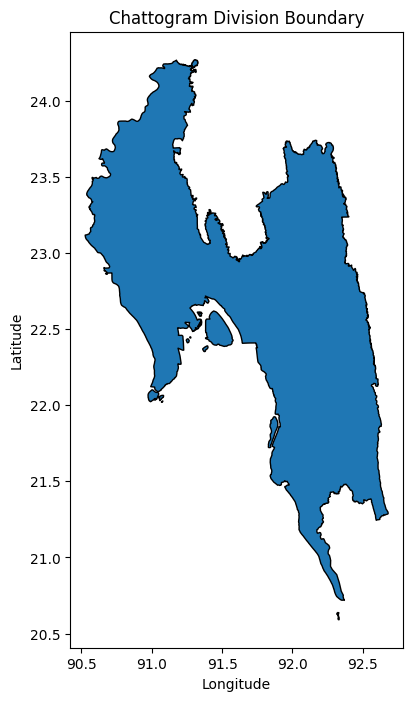

In [4]:
# ============================================================
# CELL 4 — EXTRACT CHATTOGRAM DIVISION BOUNDARY
# ============================================================

import geopandas as gpd
import os

print("=" * 70)
print("EXTRACTING CHATTOGRAM DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Extract Chattogram
# ------------------------------------------------------------

chattogram = admin1[
    admin1["adm1_name"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("chattogram")
].copy()

if len(chattogram) == 0:
    raise ValueError("❌ Chattogram Division not found.")

print("\n✅ Chattogram Division extracted.")

# ------------------------------------------------------------
# 2. Basic information
# ------------------------------------------------------------

row = chattogram.iloc[0]

print("\nName       :", row["adm1_name"])
print("PCode      :", row["adm1_pcode"])
print("Area attr. :", round(float(row["area_sqkm"]), 2), "sq.km")
print("CRS        :", chattogram.crs)

xmin, ymin, xmax, ymax = chattogram.total_bounds

print("\nBounding Box:")
print("West  :", xmin)
print("South :", ymin)
print("East  :", xmax)
print("North :", ymax)

print("\nCenter coordinates:")
print("Latitude  :", row["center_lat"])
print("Longitude :", row["center_lon"])

# ------------------------------------------------------------
# 3. Save boundary
# ------------------------------------------------------------

CHATTOGRAM_DIR = "/content/chattogram_boundary"

os.makedirs(
    CHATTOGRAM_DIR,
    exist_ok=True
)

CHATTOGRAM_SHP = os.path.join(
    CHATTOGRAM_DIR,
    "Chattogram_Division.shp"
)

chattogram.to_file(
    CHATTOGRAM_SHP
)

print("\n✅ Chattogram boundary saved:")
print(CHATTOGRAM_SHP)

# ------------------------------------------------------------
# 4. Quick map
# ------------------------------------------------------------

ax = chattogram.plot(
    figsize=(8, 8),
    edgecolor="black"
)

ax.set_title(
    "Chattogram Division Boundary"
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

print(
    "\n✅ Chattogram Division extraction complete."
)

In [5]:
# ============================================================
# CELL 5 — GOOGLE EARTH ENGINE AUTH + CHATTOGRAM ROI
# ============================================================

import ee

print("=" * 70)
print("GOOGLE EARTH ENGINE SETUP")
print("=" * 70)

# ------------------------------------------------------------
# 1. Initialize Earth Engine
# ------------------------------------------------------------

try:
    ee.Initialize(project="solid-garden-458417-t4")
    print("\n✅ Earth Engine initialized successfully.")

except Exception:

    print("\nEarth Engine authentication required...")

    ee.Authenticate()

    ee.Initialize(
        project="solid-garden-458417-t4"
    )

    print(
        "\n✅ Earth Engine authenticated and initialized."
    )

# ------------------------------------------------------------
# 2. Prepare Chattogram geometry only
# ------------------------------------------------------------

chattogram_wgs84 = (
    chattogram
    .to_crs("EPSG:4326")
)

# Use geometry only
chattogram_geom = (
    chattogram_wgs84
    .geometry
    .union_all()
)

# Convert to Earth Engine geometry
roi = ee.Geometry(
    chattogram_geom.__geo_interface__
)

print(
    "\n✅ Chattogram boundary converted to Earth Engine ROI."
)

# ------------------------------------------------------------
# 3. Earth Engine area check
# ------------------------------------------------------------

ee_area_m2 = (
    roi
    .area(maxError=1)
    .getInfo()
)

ee_area_km2 = (
    ee_area_m2 / 1e6
)

shp_area = float(
    chattogram.iloc[0]["area_sqkm"]
)

print("\n" + "=" * 70)
print("CHATTOGRAM ROI CHECK")
print("=" * 70)

print(
    "Shapefile area attribute :",
    round(shp_area, 2),
    "sq.km"
)

print(
    "Earth Engine ROI area    :",
    round(ee_area_km2, 2),
    "sq.km"
)

print(
    "Area difference          :",
    round(
        abs(
            ee_area_km2 - shp_area
        ),
        2
    ),
    "sq.km"
)

# ------------------------------------------------------------
# 4. Bounding box
# ------------------------------------------------------------

xmin, ymin, xmax, ymax = (
    chattogram_wgs84.total_bounds
)

print("\nBounding Box:")

print("West  :", xmin)
print("South :", ymin)
print("East  :", xmax)
print("North :", ymax)

# ------------------------------------------------------------
# 5. Quick SRTM test
# ------------------------------------------------------------

srtm = (
    ee.Image("USGS/SRTMGL1_003")
    .clip(roi)
)

test_stats = srtm.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=roi,
    scale=1000,
    maxPixels=1e9,
    bestEffort=True
).getInfo()

print("\nSRTM test:")
print(test_stats)

print(
    "\n✅ Earth Engine setup and Chattogram ROI verification complete."
)

GOOGLE EARTH ENGINE SETUP

Earth Engine authentication required...


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python



✅ Earth Engine authenticated and initialized.

✅ Chattogram boundary converted to Earth Engine ROI.

CHATTOGRAM ROI CHECK
Shapefile area attribute : 32833.08 sq.km
Earth Engine ROI area    : 32914.74 sq.km
Area difference          : 81.66 sq.km

Bounding Box:
West  : 90.52720869199999
South : 20.590608254000188
East  : 92.68005782300008
North : 24.269012586000088

SRTM test:
{'elevation_max': 920, 'elevation_min': -1}

✅ Earth Engine setup and Chattogram ROI verification complete.


In [7]:
# ============================================================
# CELL 6 — SENTINEL-2 COLLECTION CHECK
# CHATTOGRAM DIVISION | JAN–MAR 2025
# ============================================================

import ee

print("=" * 70)
print("SENTINEL-2 COLLECTION CHECK — CHATTOGRAM DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Date range
# ------------------------------------------------------------

START_DATE = "2025-01-01"
END_DATE   = "2025-04-01"   # exclusive

# ------------------------------------------------------------
# 2. Sentinel-2 Surface Reflectance Harmonized
# ------------------------------------------------------------

s2 = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(roi)
    .filterDate(START_DATE, END_DATE)
    .filter(
        ee.Filter.lte(
            "CLOUDY_PIXEL_PERCENTAGE",
            30
        )
    )
)

# ------------------------------------------------------------
# 3. Scene count
# ------------------------------------------------------------

scene_count = s2.size().getInfo()

print("\nDate range:")
print("Start :", START_DATE)
print("End   :", "2025-03-31")

print("\nCloud filter:")
print("CLOUDY_PIXEL_PERCENTAGE <= 30%")

print("\nTotal Sentinel-2 scenes :", scene_count)

# ------------------------------------------------------------
# 4. Unique acquisition dates
# ------------------------------------------------------------

date_list = (
    s2.aggregate_array("system:time_start")
    .map(
        lambda t:
        ee.Date(t).format("YYYY-MM-dd")
    )
    .distinct()
    .sort()
    .getInfo()
)

print(
    "Unique acquisition dates :",
    len(date_list)
)

print("\nFirst 10 dates:")
for d in date_list[:10]:
    print(" -", d)

print("\nLast 10 dates:")
for d in date_list[-10:]:
    print(" -", d)

# ------------------------------------------------------------
# 5. MGRS tiles
# ------------------------------------------------------------

tile_ids = (
    s2.aggregate_array("MGRS_TILE")
    .distinct()
    .sort()
    .getInfo()
)

print(
    "\nUnique MGRS tiles :",
    len(tile_ids)
)

print(tile_ids)

# ------------------------------------------------------------
# 6. First-image check
# ------------------------------------------------------------

if scene_count > 0:

    first_img = ee.Image(
        s2.first()
    )

    first_date = ee.Date(
        first_img.get("system:time_start")
    ).format(
        "YYYY-MM-dd"
    ).getInfo()

    first_cloud = (
        first_img
        .get("CLOUDY_PIXEL_PERCENTAGE")
        .getInfo()
    )

    first_tile = (
        first_img
        .get("MGRS_TILE")
        .getInfo()
    )

    print("\nFirst image:")
    print("Date      :", first_date)
    print("MGRS tile :", first_tile)
    print(
        "Cloud (%) :",
        round(first_cloud, 2)
    )

else:

    raise ValueError(
        "❌ No Sentinel-2 scenes found."
    )

print(
    "\n✅ Sentinel-2 collection check complete."
)

SENTINEL-2 COLLECTION CHECK — CHATTOGRAM DIVISION

Date range:
Start : 2025-01-01
End   : 2025-03-31

Cloud filter:
CLOUDY_PIXEL_PERCENTAGE <= 30%

Total Sentinel-2 scenes : 292
Unique acquisition dates : 35

First 10 dates:
 - 2025-01-02
 - 2025-01-05
 - 2025-01-07
 - 2025-01-10
 - 2025-01-12
 - 2025-01-15
 - 2025-01-17
 - 2025-01-20
 - 2025-01-22
 - 2025-01-25

Last 10 dates:
 - 2025-03-06
 - 2025-03-08
 - 2025-03-11
 - 2025-03-13
 - 2025-03-16
 - 2025-03-21
 - 2025-03-23
 - 2025-03-26
 - 2025-03-28
 - 2025-03-31

Unique MGRS tiles : 15
['45QZE', '45QZF', '45QZG', '46QBK', '46QBL', '46QBM', '46QCJ', '46QCK', '46QCL', '46QCM', '46QDH', '46QDJ', '46QDK', '46QDL', '46QDM']

First image:
Date      : 2025-01-02
MGRS tile : 46QDH
Cloud (%) : 6.9

✅ Sentinel-2 collection check complete.


In [8]:
# ============================================================
# CELL 7 — CLOUD MASK + SENTINEL-2 MEDIAN COMPOSITE
# CHATTOGRAM DIVISION
# ============================================================

import ee

print("=" * 70)
print("SENTINEL-2 CLOUD MASK + COMPOSITE — CHATTOGRAM")
print("=" * 70)

# ------------------------------------------------------------
# 1. Cloud masking function
# ------------------------------------------------------------

def mask_s2_clouds(img):

    scl = img.select("SCL")

    # Remove:
    # 3  = Cloud shadow
    # 8  = Cloud medium probability
    # 9  = Cloud high probability
    # 10 = Cirrus
    # 11 = Snow / ice

    mask = (
        scl.neq(3)
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    spectral = img.select(
        ["B2", "B3", "B4", "B8", "B11", "B12"]
    )

    return (
        spectral
        .updateMask(mask)
        .divide(10000)
        .copyProperties(
            img,
            ["system:time_start"]
        )
    )

# ------------------------------------------------------------
# 2. Apply cloud mask
# ------------------------------------------------------------

s2_clean = s2.map(
    mask_s2_clouds
)

print("\n✅ Cloud masking applied.")

# ------------------------------------------------------------
# 3. Median composite
# ------------------------------------------------------------

s2_composite = (
    s2_clean
    .median()
    .clip(roi)
)

print("✅ Median composite created.")

# ------------------------------------------------------------
# 4. Check bands
# ------------------------------------------------------------

bands = s2_composite.bandNames().getInfo()

print("\nComposite bands:")
print(bands)

print("\nBand meaning:")
print("B2  = Blue")
print("B3  = Green")
print("B4  = Red")
print("B8  = NIR")
print("B11 = SWIR1")
print("B12 = SWIR2")

print("\n✅ Sentinel-2 composite ready.")

SENTINEL-2 CLOUD MASK + COMPOSITE — CHATTOGRAM

✅ Cloud masking applied.
✅ Median composite created.

Composite bands:
['B2', 'B3', 'B4', 'B8', 'B11', 'B12']

Band meaning:
B2  = Blue
B3  = Green
B4  = Red
B8  = NIR
B11 = SWIR1
B12 = SWIR2

✅ Sentinel-2 composite ready.


In [9]:
# ============================================================
# CELL 8 — SENTINEL-2 SPECTRAL INDICES
# CHATTOGRAM DIVISION
# NDVI, NDBI, MNDWI, BSI
# ============================================================

import ee

print("=" * 70)
print("SENTINEL-2 INDEX CALCULATION — CHATTOGRAM")
print("=" * 70)

# ------------------------------------------------------------
# 1. NDVI
# (NIR - Red) / (NIR + Red)
# ------------------------------------------------------------

ndvi = (
    s2_composite
    .normalizedDifference(["B8", "B4"])
    .rename("NDVI")
)

# ------------------------------------------------------------
# 2. NDBI
# (SWIR1 - NIR) / (SWIR1 + NIR)
# ------------------------------------------------------------

ndbi = (
    s2_composite
    .normalizedDifference(["B11", "B8"])
    .rename("NDBI")
)

# ------------------------------------------------------------
# 3. MNDWI
# (Green - SWIR1) / (Green + SWIR1)
# ------------------------------------------------------------

mndwi = (
    s2_composite
    .normalizedDifference(["B3", "B11"])
    .rename("MNDWI")
)

# ------------------------------------------------------------
# 4. BSI
# ((SWIR1 + Red) - (NIR + Blue))
# --------------------------------
# ((SWIR1 + Red) + (NIR + Blue))
# ------------------------------------------------------------

bsi = s2_composite.expression(
    """
    ((SWIR1 + RED) - (NIR + BLUE)) /
    ((SWIR1 + RED) + (NIR + BLUE))
    """,
    {
        "SWIR1": s2_composite.select("B11"),
        "RED":   s2_composite.select("B4"),
        "NIR":   s2_composite.select("B8"),
        "BLUE":  s2_composite.select("B2")
    }
).rename("BSI")

# ------------------------------------------------------------
# 5. Combine indices
# ------------------------------------------------------------

s2_indices = (
    ndvi
    .addBands(ndbi)
    .addBands(mndwi)
    .addBands(bsi)
    .clip(roi)
)

print("\n✅ NDVI calculated")
print("✅ NDBI calculated")
print("✅ MNDWI calculated")
print("✅ BSI calculated")

print("\nIndex bands:")
print(s2_indices.bandNames().getInfo())

# ------------------------------------------------------------
# 6. Percentile statistics
# ------------------------------------------------------------

index_stats = s2_indices.reduceRegion(
    reducer=ee.Reducer.percentile(
        [1, 5, 25, 50, 75, 95, 99]
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("INDEX PERCENTILE STATISTICS")
print("=" * 70)

for key in sorted(index_stats.keys()):

    value = index_stats[key]

    if value is not None:
        print(f"{key:15s}: {value:.4f}")
    else:
        print(f"{key:15s}: None")

print("\n✅ Sentinel-2 indices ready.")

SENTINEL-2 INDEX CALCULATION — CHATTOGRAM

✅ NDVI calculated
✅ NDBI calculated
✅ MNDWI calculated
✅ BSI calculated

Index bands:
['NDVI', 'NDBI', 'MNDWI', 'BSI']

INDEX PERCENTILE STATISTICS
BSI_p1         : -0.2988
BSI_p25        : -0.1504
BSI_p5         : -0.2363
BSI_p50        : -0.0918
BSI_p75        : -0.0215
BSI_p95        : 0.0840
BSI_p99        : 0.1504
MNDWI_p1       : -0.6131
MNDWI_p25      : -0.5196
MNDWI_p5       : -0.5819
MNDWI_p50      : -0.4335
MNDWI_p75      : -0.3477
MNDWI_p95      : 0.5899
MNDWI_p99      : 0.7461
NDBI_p1        : -0.6835
NDBI_p25       : -0.2226
NDBI_p5        : -0.3788
NDBI_p50       : -0.1523
NDBI_p75       : -0.0743
NDBI_p95       : 0.0429
NDBI_p99       : 0.1210
NDVI_p1        : -0.2930
NDVI_p25       : 0.4571
NDVI_p5        : -0.0742
NDVI_p50       : 0.5742
NDVI_p75       : 0.6601
NDVI_p95       : 0.7617
NDVI_p99       : 0.8084

✅ Sentinel-2 indices ready.


In [10]:
# ============================================================
# CELL 9 — BUILT-UP RAW SCORE
# CHATTOGRAM DIVISION
# SAME METHOD AS DHAKA / KHULNA
# ============================================================

import ee

print("=" * 70)
print("BUILT-UP RAW SCORE — CHATTOGRAM")
print("=" * 70)

# ------------------------------------------------------------
# 1. Normalize indices from [-1, +1] to [0, 1]
# ------------------------------------------------------------

ndbi_n = (
    ndbi.add(1)
    .divide(2)
    .clamp(0, 1)
)

bsi_n = (
    bsi.add(1)
    .divide(2)
    .clamp(0, 1)
)

ndvi_n = (
    ndvi.add(1)
    .divide(2)
    .clamp(0, 1)
)

mndwi_n = (
    mndwi.add(1)
    .divide(2)
    .clamp(0, 1)
)

# ------------------------------------------------------------
# 2. Inverse vegetation / water tendency
# ------------------------------------------------------------

inv_ndvi = (
    ee.Image(1)
    .subtract(ndvi_n)
)

inv_mndwi = (
    ee.Image(1)
    .subtract(mndwi_n)
)

# ------------------------------------------------------------
# 3. Weighted built-up raw score
# ------------------------------------------------------------

builtup_raw = (
    ndbi_n.multiply(0.40)
    .add(
        bsi_n.multiply(0.25)
    )
    .add(
        inv_ndvi.multiply(0.20)
    )
    .add(
        inv_mndwi.multiply(0.15)
    )
    .rename("Builtup_Raw")
)

# ------------------------------------------------------------
# 4. Water + dense vegetation masks
# ------------------------------------------------------------

water_mask = (
    mndwi.gt(0)
)

dense_veg_mask = (
    ndvi.gt(0.45)
)

valid_builtup_mask = (
    water_mask.Not()
    .And(
        dense_veg_mask.Not()
    )
)

builtup_raw_masked = (
    builtup_raw
    .updateMask(valid_builtup_mask)
    .clip(roi)
)

print("\n✅ Weighted built-up raw score created.")
print("✅ Water mask applied      : MNDWI > 0")
print("✅ Dense vegetation masked : NDVI > 0.45")

# ------------------------------------------------------------
# 5. Percentile statistics
# ------------------------------------------------------------

builtup_stats = (
    builtup_raw_masked
    .reduceRegion(
        reducer=ee.Reducer.percentile(
            [1, 5, 25, 50, 75, 90, 95, 99]
        ),
        geometry=roi,
        scale=100,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

print("\n" + "=" * 70)
print("BUILT-UP RAW SCORE PERCENTILES")
print("=" * 70)

for key in sorted(builtup_stats.keys()):

    val = builtup_stats[key]

    if val is not None:
        print(
            f"{key:20s}: "
            f"{val:.4f}"
        )
    else:
        print(
            f"{key:20s}: None"
        )

# ------------------------------------------------------------
# 6. Valid built-up search area
# ------------------------------------------------------------

mask_area = (
    ee.Image.pixelArea()
    .updateMask(valid_builtup_mask)
    .reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=roi,
        scale=100,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .get("area")
)

mask_area_km2 = (
    ee.Number(mask_area)
    .divide(1e6)
    .getInfo()
)

mask_percent = (
    mask_area_km2
    / ee_area_km2
    * 100
)

print("\n" + "=" * 70)
print("VALID BUILT-UP SEARCH AREA")
print("=" * 70)

print(
    "Valid non-water/non-dense-veg area :",
    round(mask_area_km2, 2),
    "sq.km"
)

print(
    "Share of Chattogram ROI            :",
    round(mask_percent, 2),
    "%"
)

print("\n✅ Built-up raw score ready.")

BUILT-UP RAW SCORE — CHATTOGRAM

✅ Weighted built-up raw score created.
✅ Water mask applied      : MNDWI > 0
✅ Dense vegetation masked : NDVI > 0.45

BUILT-UP RAW SCORE PERCENTILES
Builtup_Raw_p1      : 0.3955
Builtup_Raw_p25     : 0.4658
Builtup_Raw_p5      : 0.4248
Builtup_Raw_p50     : 0.4912
Builtup_Raw_p75     : 0.5185
Builtup_Raw_p90     : 0.5420
Builtup_Raw_p95     : 0.5537
Builtup_Raw_p99     : 0.5713

VALID BUILT-UP SEARCH AREA
Valid non-water/non-dense-veg area : 5256.03 sq.km
Share of Chattogram ROI            : 15.97 %

✅ Built-up raw score ready.


In [11]:
# ============================================================
# CELL 10 — NORMALIZE BUILT-UP SCORE TO 0–1
# CHATTOGRAM DIVISION
# ============================================================

import ee

print("=" * 70)
print("BUILT-UP SCORE NORMALIZATION — CHATTOGRAM")
print("=" * 70)

# ------------------------------------------------------------
# 1. Get P5 and P99
# ------------------------------------------------------------

p5 = float(
    builtup_stats["Builtup_Raw_p5"]
)

p99 = float(
    builtup_stats["Builtup_Raw_p99"]
)

print("\nNormalization limits:")
print("P5  :", round(p5, 4))
print("P99 :", round(p99, 4))

# ------------------------------------------------------------
# 2. Normalize to 0–1
# ------------------------------------------------------------

builtup_score = (
    builtup_raw_masked
    .subtract(p5)
    .divide(p99 - p5)
    .clamp(0, 1)
    .rename("Builtup_Score")
)

print("\n✅ Built-up score normalized to 0–1.")

# ------------------------------------------------------------
# 3. Percentile statistics
# ------------------------------------------------------------

score_stats = builtup_score.reduceRegion(
    reducer=ee.Reducer.percentile(
        [1, 5, 25, 50, 75, 90, 95, 99]
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("NORMALIZED BUILT-UP SCORE PERCENTILES")
print("=" * 70)

for key in sorted(score_stats.keys()):

    val = score_stats[key]

    if val is not None:
        print(
            f"{key:22s}: "
            f"{val:.4f}"
        )
    else:
        print(
            f"{key:22s}: None"
        )

# ------------------------------------------------------------
# 4. Range check
# ------------------------------------------------------------

minmax = builtup_score.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("FINAL RANGE CHECK")
print("=" * 70)

print(
    "Minimum :",
    round(
        minmax["Builtup_Score_min"],
        4
    )
)

print(
    "Maximum :",
    round(
        minmax["Builtup_Score_max"],
        4
    )
)

print("\n✅ Built-up factor score ready.")

BUILT-UP SCORE NORMALIZATION — CHATTOGRAM

Normalization limits:
P5  : 0.4248
P99 : 0.5713

✅ Built-up score normalized to 0–1.

NORMALIZED BUILT-UP SCORE PERCENTILES
Builtup_Score_p1      : 0.0002
Builtup_Score_p25     : 0.2773
Builtup_Score_p5      : 0.0002
Builtup_Score_p50     : 0.4570
Builtup_Score_p75     : 0.6445
Builtup_Score_p90     : 0.8008
Builtup_Score_p95     : 0.8788
Builtup_Score_p99     : 0.9961

FINAL RANGE CHECK
Minimum : 0
Maximum : 1

✅ Built-up factor score ready.


In [12]:
# ============================================================
# CELL 11 — VIIRS NIGHTTIME LIGHT
# CHATTOGRAM DIVISION
# SAME METHOD AS DHAKA
# ============================================================

import ee

print("=" * 70)
print("VIIRS NIGHTTIME LIGHT — CHATTOGRAM DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load VIIRS monthly composites
# ------------------------------------------------------------

viirs = (
    ee.ImageCollection("NOAA/VIIRS/DNB/MONTHLY_V1/VCMCFG")
    .filterBounds(roi)
    .filterDate("2025-01-01", "2025-04-01")
    .select("avg_rad")
)

viirs_count = viirs.size().getInfo()

print("\nVIIRS monthly images found:", viirs_count)

if viirs_count == 0:
    raise ValueError("❌ No VIIRS images found.")

# ------------------------------------------------------------
# 2. Jan–Mar mean composite
# ------------------------------------------------------------

viirs_mean = (
    viirs
    .mean()
    .clip(roi)
    .rename("VIIRS_Mean_Radiance")
)

print("\n✅ VIIRS Jan–Mar 2025 mean composite created.")

# ------------------------------------------------------------
# 3. Statistics
# ------------------------------------------------------------

viirs_stats = viirs_mean.reduceRegion(
    reducer=(
        ee.Reducer.percentile(
            [1, 5, 25, 50, 75, 90, 95, 99]
        )
        .combine(
            reducer2=ee.Reducer.minMax(),
            sharedInputs=True
        )
    ),
    geometry=roi,
    scale=500,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("VIIRS RADIANCE STATISTICS")
print("=" * 70)

for key in sorted(viirs_stats.keys()):

    val = viirs_stats[key]

    if val is not None:
        print(f"{key:26s}: {val:.4f}")
    else:
        print(f"{key:26s}: None")

print("\nBand:")
print(viirs_mean.bandNames().getInfo())

print("\n✅ VIIRS layer ready for normalization.")

VIIRS NIGHTTIME LIGHT — CHATTOGRAM DIVISION

VIIRS monthly images found: 3

✅ VIIRS Jan–Mar 2025 mean composite created.

VIIRS RADIANCE STATISTICS
VIIRS_Mean_Radiance_max   : 104.6500
VIIRS_Mean_Radiance_min   : 0.2067
VIIRS_Mean_Radiance_p1    : 0.3600
VIIRS_Mean_Radiance_p25   : 0.3600
VIIRS_Mean_Radiance_p5    : 0.3600
VIIRS_Mean_Radiance_p50   : 0.7303
VIIRS_Mean_Radiance_p75   : 0.7303
VIIRS_Mean_Radiance_p90   : 1.1933
VIIRS_Mean_Radiance_p95   : 2.2226
VIIRS_Mean_Radiance_p99   : 7.7367

Band:
['VIIRS_Mean_Radiance']

✅ VIIRS layer ready for normalization.


In [13]:
# ============================================================
# CELL 12 — NORMALIZE VIIRS NIGHT LIGHT SCORE
# CHATTOGRAM DIVISION
# ============================================================

import ee

print("=" * 70)
print("VIIRS NIGHT LIGHT SCORE — CHATTOGRAM")
print("=" * 70)

# ------------------------------------------------------------
# 1. P5 and P99
# ------------------------------------------------------------

VIIRS_P5 = float(
    viirs_stats["VIIRS_Mean_Radiance_p5"]
)

VIIRS_P99 = float(
    viirs_stats["VIIRS_Mean_Radiance_p99"]
)

print("\nNormalization limits:")
print("P5  :", VIIRS_P5)
print("P99 :", VIIRS_P99)

# ------------------------------------------------------------
# 2. Normalize to 0–1
# ------------------------------------------------------------

night_light_score = (
    viirs_mean
    .subtract(VIIRS_P5)
    .divide(VIIRS_P99 - VIIRS_P5)
    .clamp(0, 1)
    .rename("Night_Light_Score")
)

print("\n✅ Night Light Score created.")

# ------------------------------------------------------------
# 3. Percentile check
# ------------------------------------------------------------

ntl_stats = night_light_score.reduceRegion(
    reducer=ee.Reducer.percentile(
        [25, 50, 75, 90, 95, 99]
    ),
    geometry=roi,
    scale=500,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("NORMALIZED NIGHT LIGHT SCORE")
print("=" * 70)

for key in sorted(ntl_stats.keys()):

    val = ntl_stats[key]

    if val is not None:
        print(f"{key:25s}: {val:.4f}")
    else:
        print(f"{key:25s}: None")

# ------------------------------------------------------------
# 4. Range check
# ------------------------------------------------------------

ntl_minmax = night_light_score.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=roi,
    scale=500,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("FINAL RANGE CHECK")
print("=" * 70)

print(
    "Minimum :",
    round(
        ntl_minmax["Night_Light_Score_min"],
        4
    )
)

print(
    "Maximum :",
    round(
        ntl_minmax["Night_Light_Score_max"],
        4
    )
)

print("\n✅ VIIRS Night Light factor ready.")

VIIRS NIGHT LIGHT SCORE — CHATTOGRAM

Normalization limits:
P5  : 0.36000542467883045
P99 : 7.736667188015788

✅ Night Light Score created.

NORMALIZED NIGHT LIGHT SCORE
Night_Light_Score_p25    : 0.0011
Night_Light_Score_p50    : 0.0273
Night_Light_Score_p75    : 0.0819
Night_Light_Score_p90    : 0.1521
Night_Light_Score_p95    : 0.2460
Night_Light_Score_p99    : 0.9731

FINAL RANGE CHECK
Minimum : 0
Maximum : 1

✅ VIIRS Night Light factor ready.


In [14]:
# ============================================================
# CELL 13 — GHSL POPULATION 2025
# CHATTOGRAM DIVISION
# SAME METHOD AS DHAKA
# ============================================================

import ee

print("=" * 70)
print("GHSL POPULATION 2025 — CHATTOGRAM DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load 2025 GHSL population
# ------------------------------------------------------------

population = (
    ee.ImageCollection("JRC/GHSL/P2023A/GHS_POP")
    .filter(
        ee.Filter.eq(
            "system:index",
            "2025"
        )
    )
    .first()
    .select("population_count")
    .clip(roi)
    .rename("Population")
)

print("\n✅ GHSL 2025 population layer loaded.")

print("\nBand:")
print(population.bandNames().getInfo())

# ------------------------------------------------------------
# 2. Raw population statistics
# ------------------------------------------------------------

pop_stats = population.reduceRegion(
    reducer=(
        ee.Reducer.percentile(
            [1, 5, 25, 50, 75, 90, 95, 99]
        )
        .combine(
            reducer2=ee.Reducer.minMax(),
            sharedInputs=True
        )
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("RAW POPULATION STATISTICS")
print("=" * 70)

for key in sorted(pop_stats.keys()):

    val = pop_stats[key]

    if val is not None:
        print(f"{key:22s}: {val:.4f}")
    else:
        print(f"{key:22s}: None")

print("\n✅ Population layer ready.")

GHSL POPULATION 2025 — CHATTOGRAM DIVISION

✅ GHSL 2025 population layer loaded.

Band:
['Population']

RAW POPULATION STATISTICS
Population_max        : 3403.6274
Population_min        : -200.0000
Population_p1         : 0.9412
Population_p25        : 0.9412
Population_p5         : 0.9412
Population_p50        : 0.9412
Population_p75        : 0.9412
Population_p90        : 23.2483
Population_p95        : 55.3418
Population_p99        : 151.6056

✅ Population layer ready.


In [15]:
# ============================================================
# CELL 14 — GHSL POPULATION SCORE
# CHATTOGRAM DIVISION
# Clean negative values + log transform + normalization
# ============================================================

import ee

print("=" * 70)
print("GHSL POPULATION SCORE — CHATTOGRAM")
print("=" * 70)

# ------------------------------------------------------------
# 1. Clean invalid negative population
# ------------------------------------------------------------

population_clean = (
    population
    .where(
        population.lt(0),
        0
    )
    .rename("Population_Clean")
)

print("\n✅ Negative/fill values replaced with 0.")

# ------------------------------------------------------------
# 2. Log transform
# log(1 + population)
# ------------------------------------------------------------

population_log = (
    population_clean
    .add(1)
    .log()
    .rename("Population_Log")
)

print("✅ Log transformation completed.")

# ------------------------------------------------------------
# 3. Raw P99 -> log-space P99
# ------------------------------------------------------------

POP_P99 = float(
    pop_stats["Population_p99"]
)

LOG_P99 = (
    ee.Number(POP_P99)
    .add(1)
    .log()
    .getInfo()
)

print("\nNormalization reference:")
print("Raw Population P99 :", round(POP_P99, 4))
print("Log Population P99 :", round(LOG_P99, 4))

# ------------------------------------------------------------
# 4. Normalize to 0–1
# ------------------------------------------------------------

population_score = (
    population_log
    .divide(LOG_P99)
    .clamp(0, 1)
    .rename("Population_Score")
)

print("\n✅ Population Score created.")

# ------------------------------------------------------------
# 5. Percentile check
# ------------------------------------------------------------

population_score_stats = population_score.reduceRegion(
    reducer=ee.Reducer.percentile(
        [25, 50, 75, 90, 95, 99]
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("NORMALIZED POPULATION SCORE")
print("=" * 70)

for key in sorted(population_score_stats.keys()):

    val = population_score_stats[key]

    if val is not None:
        print(f"{key:28s}: {val:.4f}")
    else:
        print(f"{key:28s}: None")

# ------------------------------------------------------------
# 6. Min-max check
# ------------------------------------------------------------

population_minmax = population_score.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("FINAL RANGE CHECK")
print("=" * 70)

print(
    "Minimum :",
    round(
        population_minmax["Population_Score_min"],
        4
    )
)

print(
    "Maximum :",
    round(
        population_minmax["Population_Score_max"],
        4
    )
)

print("\n✅ GHSL Population factor ready.")

GHSL POPULATION SCORE — CHATTOGRAM

✅ Negative/fill values replaced with 0.
✅ Log transformation completed.

Normalization reference:
Raw Population P99 : 151.6056
Log Population P99 : 5.0279

✅ Population Score created.

NORMALIZED POPULATION SCORE
Population_Score_p25        : 0.0000
Population_Score_p50        : 0.0000
Population_Score_p75        : 0.1677
Population_Score_p90        : 0.6758
Population_Score_p95        : 0.8008
Population_Score_p99        : 0.9961

FINAL RANGE CHECK
Minimum : 0
Maximum : 1

✅ GHSL Population factor ready.


In [16]:
# ============================================================
# CELL 15 — GRIP4 ROAD NETWORK CHECK
# CHATTOGRAM DIVISION
# ============================================================

import ee

print("=" * 70)
print("GRIP4 ROAD NETWORK — CHATTOGRAM DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load GRIP4 South-East Asia road network
# ------------------------------------------------------------

roads_all = ee.FeatureCollection(
    "projects/sat-io/open-datasets/GRIP4/South-East-Asia"
)

# Roads intersecting Chattogram ROI
roads = roads_all.filterBounds(roi)

road_count = roads.size().getInfo()

print("\nGRIP4 roads intersecting Chattogram:")
print(road_count)

if road_count == 0:
    raise ValueError("❌ No GRIP4 roads found.")

# ------------------------------------------------------------
# 2. First feature properties
# ------------------------------------------------------------

first_road = ee.Feature(roads.first())

first_properties = first_road.toDictionary().getInfo()

print("\n" + "=" * 70)
print("FIRST ROAD FEATURE PROPERTIES")
print("=" * 70)

for key, value in first_properties.items():
    print(f"{key}: {value}")

# ------------------------------------------------------------
# 3. GP_RTP road class distribution
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GRIP4 ROAD CLASS DISTRIBUTION")
print("=" * 70)

class_hist = (
    roads
    .aggregate_histogram("GP_RTP")
    .getInfo()
)

total_check = 0

for road_class in ["1", "2", "3", "4", "5"]:

    count = class_hist.get(
        road_class,
        class_hist.get(
            int(road_class),
            0
        )
    )

    total_check += count

    print(
        f"GP_RTP Class {road_class}: "
        f"{count}"
    )

print("-" * 40)
print("Total classified roads:", total_check)
print("Total intersecting roads:", road_count)

print("\nRoad weights for next step:")
print("Class 1 = 1.00")
print("Class 2 = 0.85")
print("Class 3 = 0.70")
print("Class 4 = 0.45")
print("Class 5 = 0.25")

print("\n✅ GRIP4 road network ready.")

GRIP4 ROAD NETWORK — CHATTOGRAM DIVISION

GRIP4 roads intersecting Chattogram:
18404

FIRST ROAD FEATURE PROPERTIES
GP_RAV: 1
GP_RCY: 50
GP_REX: 1
GP_RRG: 18
GP_RSE: 1
GP_RSI: 51
GP_RSY: 2006
GP_RTP: 4
Shape_Leng: 0.00851124835358
gp_gripreg: 6

GRIP4 ROAD CLASS DISTRIBUTION
GP_RTP Class 1: 142
GP_RTP Class 2: 645
GP_RTP Class 3: 933
GP_RTP Class 4: 13690
GP_RTP Class 5: 2994
----------------------------------------
Total classified roads: 18404
Total intersecting roads: 18404

Road weights for next step:
Class 1 = 1.00
Class 2 = 0.85
Class 3 = 0.70
Class 4 = 0.45
Class 5 = 0.25

✅ GRIP4 road network ready.


In [17]:
# ============================================================
# CELL 16 — WEIGHTED ROAD DENSITY
# CHATTOGRAM DIVISION
# SAME METHOD AS DHAKA / KHULNA
# ============================================================

import ee

print("=" * 70)
print("WEIGHTED ROAD DENSITY — CHATTOGRAM")
print("=" * 70)

# ------------------------------------------------------------
# 1. Road class weights
# ------------------------------------------------------------

ROAD_WEIGHTS = {
    1: 1.00,
    2: 0.85,
    3: 0.70,
    4: 0.45,
    5: 0.25
}

print("\nRoad class weights:")
for road_class, weight in ROAD_WEIGHTS.items():
    print(
        f"GP_RTP {road_class} -> {weight}"
    )

# ------------------------------------------------------------
# 2. Add weight to road features
# ------------------------------------------------------------

def add_road_weight(feature):

    road_type = ee.Number(
        feature.get("GP_RTP")
    )

    weight = ee.Number(
        ee.Algorithms.If(
            road_type.eq(1), 1.00,
            ee.Algorithms.If(
                road_type.eq(2), 0.85,
                ee.Algorithms.If(
                    road_type.eq(3), 0.70,
                    ee.Algorithms.If(
                        road_type.eq(4), 0.45,
                        ee.Algorithms.If(
                            road_type.eq(5), 0.25,
                            0
                        )
                    )
                )
            )
        )
    )

    return feature.set(
        "road_weight",
        weight
    )

weighted_roads = roads.map(
    add_road_weight
)

print("\n✅ Road weights assigned.")

# ------------------------------------------------------------
# 3. Convert roads to raster
# ------------------------------------------------------------

road_raster = (
    weighted_roads
    .reduceToImage(
        properties=["road_weight"],
        reducer=ee.Reducer.max()
    )
    .unmask(0)
    .clip(roi)
    .rename("Road_Weight")
)

print("✅ Weighted road raster created.")

# ------------------------------------------------------------
# 4. 1 km circular neighborhood
# ------------------------------------------------------------

road_kernel = ee.Kernel.circle(
    radius=1000,
    units="meters",
    normalize=False
)

# ------------------------------------------------------------
# 5. Weighted road density
# ------------------------------------------------------------

road_density = (
    road_raster
    .reduceNeighborhood(
        reducer=ee.Reducer.mean(),
        kernel=road_kernel,
        skipMasked=True
    )
    .clip(roi)
    .rename("Road_Density")
)

print("✅ 1-km weighted road density calculated.")

# ------------------------------------------------------------
# 6. Statistics
# ------------------------------------------------------------

road_density_stats = road_density.reduceRegion(
    reducer=(
        ee.Reducer.percentile(
            [1, 5, 25, 50, 75, 90, 95, 99]
        )
        .combine(
            reducer2=ee.Reducer.minMax(),
            sharedInputs=True
        )
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("ROAD DENSITY STATISTICS")
print("=" * 70)

for key in sorted(
    road_density_stats.keys()
):

    value = road_density_stats[key]

    if value is not None:
        print(
            f"{key:25s}: "
            f"{value:.6f}"
        )
    else:
        print(
            f"{key:25s}: None"
        )

print("\n✅ Weighted road density layer ready.")

WEIGHTED ROAD DENSITY — CHATTOGRAM

Road class weights:
GP_RTP 1 -> 1.0
GP_RTP 2 -> 0.85
GP_RTP 3 -> 0.7
GP_RTP 4 -> 0.45
GP_RTP 5 -> 0.25

✅ Road weights assigned.
✅ Weighted road raster created.
✅ 1-km weighted road density calculated.

ROAD DENSITY STATISTICS
Road_Density_max         : 0.390536
Road_Density_min         : 0.000000
Road_Density_p1          : 0.000030
Road_Density_p25         : 0.000030
Road_Density_p5          : 0.000030
Road_Density_p50         : 0.041856
Road_Density_p75         : 0.086792
Road_Density_p90         : 0.126025
Road_Density_p95         : 0.149391
Road_Density_p99         : 0.194317

✅ Weighted road density layer ready.


In [18]:
# ============================================================
# CELL 17 — NORMALIZE ROAD DENSITY SCORE
# CHATTOGRAM DIVISION
# P5–P99 robust normalization
# ============================================================

import ee

print("=" * 70)
print("ROAD DENSITY SCORE — CHATTOGRAM")
print("=" * 70)

# ------------------------------------------------------------
# 1. P5 and P99
# ------------------------------------------------------------

ROAD_P5 = float(
    road_density_stats["Road_Density_p5"]
)

ROAD_P99 = float(
    road_density_stats["Road_Density_p99"]
)

print("\nNormalization limits:")
print("P5  :", ROAD_P5)
print("P99 :", ROAD_P99)

# ------------------------------------------------------------
# 2. Normalize to 0–1
# ------------------------------------------------------------

road_score = (
    road_density
    .subtract(ROAD_P5)
    .divide(ROAD_P99 - ROAD_P5)
    .clamp(0, 1)
    .rename("Road_Score")
    .clip(roi)
)

print("\n✅ Road Score created.")

# ------------------------------------------------------------
# 3. Statistics
# ------------------------------------------------------------

road_score_stats = road_score.reduceRegion(
    reducer=(
        ee.Reducer.percentile(
            [5, 25, 50, 75, 90, 95, 99]
        )
        .combine(
            reducer2=ee.Reducer.minMax(),
            sharedInputs=True
        )
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("ROAD SCORE STATISTICS")
print("=" * 70)

for key in sorted(road_score_stats.keys()):

    value = road_score_stats[key]

    if value is not None:
        print(
            f"{key:22s}: "
            f"{value:.4f}"
        )
    else:
        print(
            f"{key:22s}: None"
        )

print("\nBand:")
print(road_score.bandNames().getInfo())

print("\n✅ Road Density factor ready.")

ROAD DENSITY SCORE — CHATTOGRAM

Normalization limits:
P5  : 3.0330453791295782e-05
P99 : 0.1943171874716585

✅ Road Score created.

ROAD SCORE STATISTICS
Road_Score_max        : 1.0000
Road_Score_min        : 0.0000
Road_Score_p25        : 0.0001
Road_Score_p5         : 0.0001
Road_Score_p50        : 0.2126
Road_Score_p75        : 0.4492
Road_Score_p90        : 0.6517
Road_Score_p95        : 0.7691
Road_Score_p99        : 1.0000

Band:
['Road_Score']

✅ Road Density factor ready.


In [19]:
# ============================================================
# CELL 18 — TEST OVERTURE PLACES VIA DUCKDB
# CHATTOGRAM DIVISION
# ============================================================

!pip -q install duckdb

import duckdb
import os
import geopandas as gpd

print("=" * 70)
print("OVERTURE PLACES TEST — CHATTOGRAM")
print("=" * 70)

# ------------------------------------------------------------
# 1. Test bbox around Chattogram city
# west, south, east, north
# ------------------------------------------------------------

xmin = 91.70
ymin = 22.20
xmax = 91.95
ymax = 22.45

OUT_FILE = "/content/chattogram_overture_test.geojson"

if os.path.exists(OUT_FILE):
    os.remove(OUT_FILE)

print("\nTest bbox:")
print("West :", xmin)
print("South:", ymin)
print("East :", xmax)
print("North:", ymax)

# ------------------------------------------------------------
# 2. Start DuckDB
# ------------------------------------------------------------

con = duckdb.connect()

con.execute("INSTALL spatial;")
con.execute("LOAD spatial;")

con.execute("INSTALL httpfs;")
con.execute("LOAD httpfs;")

con.execute("SET s3_region='us-west-2';")

print("\n✅ DuckDB spatial + httpfs ready.")

# ------------------------------------------------------------
# 3. Query Overture Places
# ------------------------------------------------------------

query = f"""
COPY (
    SELECT
        id,
        names.primary AS name,
        basic_category,
        confidence,
        geometry
    FROM read_parquet(
        's3://overturemaps-us-west-2/release/2026-08-19.0/theme=places/type=place/*',
        filename=true,
        hive_partitioning=1
    )
    WHERE
        bbox.xmin <= {xmax}
        AND bbox.xmax >= {xmin}
        AND bbox.ymin <= {ymax}
        AND bbox.ymax >= {ymin}
)
TO '{OUT_FILE}'
WITH (
    FORMAT GDAL,
    DRIVER 'GeoJSON',
    SRS 'EPSG:4326'
);
"""

print("\nQuerying Overture Places...")

con.execute(query)

# ------------------------------------------------------------
# 4. Read result
# ------------------------------------------------------------

if os.path.exists(OUT_FILE):

    poi_test = gpd.read_file(OUT_FILE)

    print("\n✅ GeoJSON created")
    print("Total place features:", len(poi_test))

    print("\nColumns:")
    print(poi_test.columns.tolist())

    if len(poi_test) > 0:

        print("\nTop 20 basic categories:")
        print(
            poi_test["basic_category"]
            .fillna("UNKNOWN")
            .value_counts()
            .head(20)
        )

        print("\nFirst 5 rows:")
        display(
            poi_test[
                ["name", "basic_category", "confidence"]
            ].head()
        )

        print("\n✅ Direct Overture access is working.")

    else:
        print("\n⚠️ Query returned 0 places.")

else:
    print("\n❌ GeoJSON was not created.")

OVERTURE PLACES TEST — CHATTOGRAM

Test bbox:
West : 91.7
South: 22.2
East : 91.95
North: 22.45

✅ DuckDB spatial + httpfs ready.

Querying Overture Places...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


✅ GeoJSON created
Total place features: 16222

Columns:
['id', 'name', 'basic_category', 'confidence', 'geometry']

Top 20 basic categories:
basic_category
UNKNOWN                           965
fashion_and_apparel_store         930
restaurant                        798
historic_site                     603
professional_service              602
electronics_store                 579
place_of_learning                 531
event_or_party_service            436
college_university                388
education                         385
social_or_community_service       384
travel_service                    349
shopping                          313
hardware_home_and_garden_store    288
technical_service                 277
corporate_or_business_office      269
government_office                 264
personal_or_beauty_service        251
food_and_beverage_store           248
manufacturer                      238
Name: count, dtype: int64

First 5 rows:


,name,basic_category,confidence
0,মেসার্স সাথী ষ্টোর,food_service,0.420343
1,সৈয়দ কুচাইয়া আমির বক্স সরকারী প্রাথমিক বিদ্য...,elementary_school,0.417632
2,Recall Printing,design_service,0.441881
3,Norman's Point,historic_site,0.794089
4,S M A AGRO,b2b_service,0.737899



✅ Direct Overture access is working.


In [20]:
# ============================================================
# CELL 19 — CREATE 0.2° POI DOWNLOAD GRID
# CHATTOGRAM DIVISION
# ============================================================

import geopandas as gpd
import numpy as np
from shapely.geometry import box

print("=" * 70)
print("CREATE OVERTURE POI GRID — CHATTOGRAM")
print("=" * 70)

# ------------------------------------------------------------
# 1. Grid size
# ------------------------------------------------------------

GRID_SIZE = 0.2

# ------------------------------------------------------------
# 2. Chattogram bounds
# ------------------------------------------------------------

xmin, ymin, xmax, ymax = (
    chattogram_wgs84.total_bounds
)

print("\nChattogram bounds:")
print("West  :", xmin)
print("South :", ymin)
print("East  :", xmax)
print("North :", ymax)

# ------------------------------------------------------------
# 3. Create raw grid
# ------------------------------------------------------------

x_coords = np.arange(
    xmin,
    xmax,
    GRID_SIZE
)

y_coords = np.arange(
    ymin,
    ymax,
    GRID_SIZE
)

grid_cells = []

chunk_id = 1

for x in x_coords:

    for y in y_coords:

        cell = box(
            x,
            y,
            min(x + GRID_SIZE, xmax),
            min(y + GRID_SIZE, ymax)
        )

        grid_cells.append({
            "chunk_id": chunk_id,
            "geometry": cell
        })

        chunk_id += 1

grid = gpd.GeoDataFrame(
    grid_cells,
    crs="EPSG:4326"
)

print("\nTotal raw grid cells:", len(grid))

# ------------------------------------------------------------
# 4. Keep only cells intersecting Chattogram
# ------------------------------------------------------------

chattogram_union = (
    chattogram_wgs84
    .geometry
    .union_all()
)

grid_intersect = grid[
    grid.intersects(
        chattogram_union
    )
].copy()

grid_intersect = (
    grid_intersect
    .reset_index(drop=True)
)

grid_intersect[
    "chunk_no"
] = range(
    1,
    len(grid_intersect) + 1
)

print(
    "Intersecting grid cells:",
    len(grid_intersect)
)

# ------------------------------------------------------------
# 5. Add bbox coordinates
# ------------------------------------------------------------

bounds = (
    grid_intersect.geometry.bounds
)

grid_intersect["west"] = (
    bounds.minx
)

grid_intersect["south"] = (
    bounds.miny
)

grid_intersect["east"] = (
    bounds.maxx
)

grid_intersect["north"] = (
    bounds.maxy
)

# ------------------------------------------------------------
# 6. Preview
# ------------------------------------------------------------

print("\nFirst 10 intersecting chunks:")

display(
    grid_intersect[
        [
            "chunk_no",
            "west",
            "south",
            "east",
            "north"
        ]
    ].head(10)
)

print("\nGrid size :", GRID_SIZE, "degree")

print(
    "Total intersecting chunks :",
    len(grid_intersect)
)

print(
    "\n✅ Chattogram POI grid ready."
)

CREATE OVERTURE POI GRID — CHATTOGRAM

Chattogram bounds:
West  : 90.52720869199999
South : 20.590608254000188
East  : 92.68005782300008
North : 24.269012586000088

Total raw grid cells: 209
Intersecting grid cells: 112

First 10 intersecting chunks:


,chunk_no,west,south,east,north
0,1,90.527209,22.790608,90.727209,22.990608
1,2,90.527209,22.990608,90.727209,23.190608
2,3,90.527209,23.190608,90.727209,23.390608
3,4,90.527209,23.390608,90.727209,23.590608
4,5,90.527209,23.590608,90.727209,23.790608
5,6,90.727209,22.390608,90.927209,22.590608
6,7,90.727209,22.590608,90.927209,22.790608
7,8,90.727209,22.790608,90.927209,22.990608
8,9,90.727209,22.990608,90.927209,23.190608
9,10,90.727209,23.190608,90.927209,23.390608



Grid size : 0.2 degree
Total intersecting chunks : 112

✅ Chattogram POI grid ready.


In [21]:
# ============================================================
# CELL 20 — SINGLE-CHUNK OVERTURE POI TEST
# CHATTOGRAM DIVISION
# Same 48-category urban POI filter
# ============================================================

import os
import duckdb
import geopandas as gpd

print("=" * 70)
print("SINGLE-CHUNK OVERTURE TEST — CHATTOGRAM")
print("=" * 70)

# ------------------------------------------------------------
# 1. Urban-relevant POI categories
# ------------------------------------------------------------

URBAN_POI_CATEGORIES = {

    # Shopping / commercial
    "shopping",
    "shopping_mall",
    "fashion_and_apparel_store",
    "electronics_store",
    "hardware_home_and_garden_store",
    "food_and_beverage_store",
    "warehouse_club_store",
    "books_music_and_video_store",
    "personal_care_and_beauty_store",
    "specialty_store",
    "farmers_market",

    # Food / restaurants
    "restaurant",
    "fast_food_restaurant",
    "casual_eatery",
    "cafe",
    "coffee_shop",
    "food_service",

    # Education
    "educational_service",
    "education",
    "place_of_learning",
    "college_university",
    "specialty_school",
    "high_school",
    "middle_school",
    "elementary_school",
    "preschool",
    "research_institute",

    # Health / medical
    "hospital",
    "health_care",
    "medical_service",
    "dental_clinic",
    "pharmacy_and_drug_store",
    "diagnostics_imaging_or_lab_service",
    "specialized_health_care",
    "specialized_medical_facility",
    "primary_care_or_general_clinic",
    "pediatric_clinic",
    "vision_or_eye_care_clinic",

    # Finance
    "bank_or_credit_union",
    "financial_service",

    # Offices / urban services
    "corporate_or_business_office",
    "government_office",
    "professional_service",
    "technical_service",
    "b2b_office_and_professional_service",

    # Accommodation
    "hotel",
    "lodging",

    # Transport
    "public_transit_facility_or_service"
}

print("\nAllowed urban categories:", len(URBAN_POI_CATEGORIES))

# ------------------------------------------------------------
# 2. Choose one middle-ish chunk
# ------------------------------------------------------------

TEST_CHUNK_NO = 50

test_row = grid_intersect[
    grid_intersect["chunk_no"] == TEST_CHUNK_NO
].iloc[0]

minx, miny, maxx, maxy = test_row.geometry.bounds

print("\nTesting chunk:", TEST_CHUNK_NO)
print(
    "BBox:",
    f"{minx:.6f}, {miny:.6f}, {maxx:.6f}, {maxy:.6f}"
)

# ------------------------------------------------------------
# 3. Output file
# ------------------------------------------------------------

raw_file = (
    f"/content/chattogram_chunk_"
    f"{TEST_CHUNK_NO}_raw.geojson"
)

if os.path.exists(raw_file):
    os.remove(raw_file)

# ------------------------------------------------------------
# 4. DuckDB direct query
# ------------------------------------------------------------

con = duckdb.connect()

con.execute("INSTALL spatial;")
con.execute("LOAD spatial;")

con.execute("INSTALL httpfs;")
con.execute("LOAD httpfs;")

con.execute("SET s3_region='us-west-2';")

query = f"""
COPY (
    SELECT
        id,
        basic_category,
        confidence,
        geometry
    FROM read_parquet(
        's3://overturemaps-us-west-2/release/2026-08-19.0/theme=places/type=place/*',
        filename=true,
        hive_partitioning=1
    )
    WHERE
        bbox.xmin <= {maxx}
        AND bbox.xmax >= {minx}
        AND bbox.ymin <= {maxy}
        AND bbox.ymax >= {miny}
)
TO '{raw_file}'
WITH (
    FORMAT GDAL,
    DRIVER 'GeoJSON',
    SRS 'EPSG:4326'
);
"""

print("\nQuerying Overture Places...")

con.execute(query)

# ------------------------------------------------------------
# 5. Read raw POIs
# ------------------------------------------------------------

poi_chunk = gpd.read_file(raw_file)

raw_count = len(poi_chunk)

print("\nRaw POIs:", raw_count)

# ------------------------------------------------------------
# 6. Urban category filter
# ------------------------------------------------------------

poi_chunk = poi_chunk[
    poi_chunk["basic_category"].isin(
        URBAN_POI_CATEGORIES
    )
].copy()

urban_count = len(poi_chunk)

print("After category filter:", urban_count)

# ------------------------------------------------------------
# 7. Keep only POIs inside Chattogram Division
# ------------------------------------------------------------

poi_chunk = gpd.sjoin(
    poi_chunk,
    chattogram_wgs84[["geometry"]],
    predicate="within",
    how="inner"
).drop(
    columns=["index_right"],
    errors="ignore"
)

inside_count = len(poi_chunk)

print("Inside Chattogram boundary:", inside_count)

# ------------------------------------------------------------
# 8. Keep lightweight fields
# ------------------------------------------------------------

poi_chunk = poi_chunk[
    [
        "id",
        "basic_category",
        "confidence",
        "geometry"
    ]
].copy()

# ------------------------------------------------------------
# 9. Delete raw file
# ------------------------------------------------------------

raw_size_mb = (
    os.path.getsize(raw_file)
    / (1024 * 1024)
)

print(
    "\nRaw file size:",
    round(raw_size_mb, 3),
    "MB"
)

os.remove(raw_file)

print("✅ Raw chunk file deleted")

# ------------------------------------------------------------
# 10. Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SINGLE-CHUNK TEST SUMMARY")
print("=" * 70)

print("Raw POIs            :", raw_count)
print("Urban category POIs :", urban_count)
print("Inside Chattogram   :", inside_count)

if raw_count > 0:

    print(
        "Urban POIs retained :",
        round(
            urban_count / raw_count * 100,
            2
        ),
        "%"
    )

print("\nTop 15 categories:")

print(
    poi_chunk["basic_category"]
    .value_counts()
    .head(15)
)

print("\nGeometry types:")
print(
    poi_chunk.geom_type
    .value_counts()
)

print(
    "\n✅ Single-chunk test completed successfully."
)

SINGLE-CHUNK OVERTURE TEST — CHATTOGRAM

Allowed urban categories: 48

Testing chunk: 50
BBox: 91.727209, 21.390608, 91.927209, 21.590608

Querying Overture Places...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Raw POIs: 12
After category filter: 3
Inside Chattogram boundary: 3

Raw file size: 0.003 MB
✅ Raw chunk file deleted

SINGLE-CHUNK TEST SUMMARY
Raw POIs            : 12
Urban category POIs : 3
Inside Chattogram   : 3
Urban POIs retained : 25.0 %

Top 15 categories:
basic_category
place_of_learning    1
high_school          1
education            1
Name: count, dtype: int64

Geometry types:
Point    3
Name: count, dtype: int64

✅ Single-chunk test completed successfully.


In [22]:
# ============================================================
# CELL 21 — PROCESS ALL CHATTOGRAM OVERTURE POI CHUNKS
# DuckDB direct S3 query
# Filter -> Clip -> Delete raw -> Merge -> Deduplicate
# ============================================================

import os
import time
import duckdb
import geopandas as gpd
import pandas as pd

print("=" * 70)
print("FULL CHATTOGRAM OVERTURE POI PROCESSING")
print("=" * 70)

OVERTURE_RELEASE = "2026-08-19.0"

total_chunks = len(grid_intersect)

all_filtered_chunks = []
failed_chunks = []

print("\nTotal chunks:", total_chunks)
print("Overture release:", OVERTURE_RELEASE)

# ------------------------------------------------------------
# 1. Start DuckDB once
# ------------------------------------------------------------

con = duckdb.connect()

con.execute("INSTALL spatial;")
con.execute("LOAD spatial;")

con.execute("INSTALL httpfs;")
con.execute("LOAD httpfs;")

con.execute("SET s3_region='us-west-2';")

print("\n✅ DuckDB ready.")

# ------------------------------------------------------------
# 2. Process every chunk
# ------------------------------------------------------------

for idx, row in grid_intersect.iterrows():

    chunk_no = int(row["chunk_no"])

    minx, miny, maxx, maxy = row.geometry.bounds

    raw_file = (
        f"/content/chattogram_chunk_"
        f"{chunk_no}_raw.geojson"
    )

    if os.path.exists(raw_file):
        os.remove(raw_file)

    print(f"\n[{chunk_no}/{total_chunks}] Processing...")

    query = f"""
    COPY (
        SELECT
            id,
            basic_category,
            confidence,
            geometry
        FROM read_parquet(
            's3://overturemaps-us-west-2/release/{OVERTURE_RELEASE}/theme=places/type=place/*',
            filename=true,
            hive_partitioning=1
        )
        WHERE
            bbox.xmin <= {maxx}
            AND bbox.xmax >= {minx}
            AND bbox.ymin <= {maxy}
            AND bbox.ymax >= {miny}
    )
    TO '{raw_file}'
    WITH (
        FORMAT GDAL,
        DRIVER 'GeoJSON',
        SRS 'EPSG:4326'
    );
    """

    try:

        con.execute(query)

    except Exception as e:

        print(
            "   ❌ Query failed:",
            str(e)[:300]
        )

        failed_chunks.append(
            chunk_no
        )

        if os.path.exists(raw_file):
            os.remove(raw_file)

        continue

    # --------------------------------------------------------
    # Check result file
    # --------------------------------------------------------

    if not os.path.exists(raw_file):

        print("   ⚠️ No output file")

        failed_chunks.append(
            chunk_no
        )

        continue

    # --------------------------------------------------------
    # Read raw chunk
    # --------------------------------------------------------

    try:

        poi_chunk = gpd.read_file(
            raw_file
        )

    except Exception as e:

        print(
            "   ❌ Read failed:",
            str(e)[:300]
        )

        failed_chunks.append(
            chunk_no
        )

        os.remove(raw_file)

        continue

    raw_count = len(
        poi_chunk
    )

    # --------------------------------------------------------
    # Urban-category filter
    # --------------------------------------------------------

    if raw_count > 0:

        poi_chunk = poi_chunk[
            poi_chunk[
                "basic_category"
            ].isin(
                URBAN_POI_CATEGORIES
            )
        ].copy()

    urban_count = len(
        poi_chunk
    )

    # --------------------------------------------------------
    # Clip to actual Chattogram boundary
    # --------------------------------------------------------

    if urban_count > 0:

        poi_chunk = gpd.sjoin(
            poi_chunk,
            chattogram_wgs84[
                ["geometry"]
            ],
            predicate="within",
            how="inner"
        ).drop(
            columns=["index_right"],
            errors="ignore"
        )

    inside_count = len(
        poi_chunk
    )

    # --------------------------------------------------------
    # Keep lightweight fields
    # --------------------------------------------------------

    if inside_count > 0:

        poi_chunk = poi_chunk[
            [
                "id",
                "basic_category",
                "confidence",
                "geometry"
            ]
        ].copy()

        all_filtered_chunks.append(
            poi_chunk
        )

    # --------------------------------------------------------
    # Delete raw file
    # --------------------------------------------------------

    if os.path.exists(raw_file):
        os.remove(raw_file)

    print(
        f"   Raw: {raw_count} | "
        f"Urban: {urban_count} | "
        f"Inside Chattogram: {inside_count}"
    )

    time.sleep(0.1)

# ============================================================
# 3. Merge all chunks
# ============================================================

if len(all_filtered_chunks) == 0:

    raise RuntimeError(
        "❌ No Chattogram POIs collected."
    )

chattogram_pois = gpd.GeoDataFrame(
    pd.concat(
        all_filtered_chunks,
        ignore_index=True
    ),
    crs="EPSG:4326"
)

# ------------------------------------------------------------
# 4. Deduplicate by Overture ID
# ------------------------------------------------------------

before_dedup = len(
    chattogram_pois
)

chattogram_pois = (
    chattogram_pois
    .drop_duplicates(
        subset="id"
    )
    .reset_index(
        drop=True
    )
)

after_dedup = len(
    chattogram_pois
)

# ------------------------------------------------------------
# 5. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FULL CHATTOGRAM POI PROCESSING COMPLETE")
print("=" * 70)

print(
    "Chunks attempted          :",
    total_chunks
)

print(
    "Failed chunks             :",
    failed_chunks
)

print(
    "POIs before deduplication :",
    before_dedup
)

print(
    "Unique urban POIs         :",
    after_dedup
)

print(
    "Duplicates removed        :",
    before_dedup - after_dedup
)

print("\nTop 20 categories:")

print(
    chattogram_pois[
        "basic_category"
    ]
    .value_counts()
    .head(20)
)

print("\nGeometry types:")

print(
    chattogram_pois
    .geom_type
    .value_counts()
)

if len(failed_chunks) == 0:

    print(
        "\n✅ ALL CHATTOGRAM CHUNKS COMPLETED."
    )

else:

    print(
        "\n⚠️ Some chunks failed."
    )

print(
    "\n✅ Chattogram urban POI dataset ready."
)

FULL CHATTOGRAM OVERTURE POI PROCESSING

Total chunks: 112
Overture release: 2026-08-19.0

✅ DuckDB ready.

[1/112] Processing...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   Raw: 30 | Urban: 15 | Inside Chattogram: 2

[2/112] Processing...
   Raw: 139 | Urban: 91 | Inside Chattogram: 87

[3/112] Processing...
   Raw: 869 | Urban: 525 | Inside Chattogram: 514

[4/112] Processing...
   Raw: 720 | Urban: 397 | Inside Chattogram: 88

[5/112] Processing...
   Raw: 1156 | Urban: 626 | Inside Chattogram: 16

[6/112] Processing...
   Raw: 36 | Urban: 23 | Inside Chattogram: 0

[7/112] Processing...
   Raw: 80 | Urban: 46 | Inside Chattogram: 28

[8/112] Processing...
   Raw: 406 | Urban: 285 | Inside Chattogram: 285

[9/112] Processing...
   Raw: 449 | Urban: 286 | Inside Chattogram: 286

[10/112] Processing...
   Raw: 461 | Urban: 304 | Inside Chattogram: 304

[11/112] Processing...
   Raw: 394 | Urban: 230 | Inside Chattogram: 230

[12/112] Processing...
   Raw: 407 | Urban: 244 | Inside Chattogram: 242

[13/112] Processing...
   Raw: 247 | Urban: 136 | Inside Chattogram: 34

[14/112] Processing...
   Raw: 27 | Urban: 13 | Inside Chattogram: 9

[15/112] Proce

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   Raw: 12 | Urban: 3 | Inside Chattogram: 3

[51/112] Processing...
   Raw: 63 | Urban: 31 | Inside Chattogram: 31

[52/112] Processing...
   Raw: 55 | Urban: 28 | Inside Chattogram: 28

[53/112] Processing...
   Raw: 98 | Urban: 46 | Inside Chattogram: 46

[54/112] Processing...
   Raw: 14963 | Urban: 8096 | Inside Chattogram: 8096

[55/112] Processing...
   Raw: 2020 | Urban: 1040 | Inside Chattogram: 1040

[56/112] Processing...
   Raw: 408 | Urban: 215 | Inside Chattogram: 215

[57/112] Processing...
   Raw: 80 | Urban: 39 | Inside Chattogram: 39

[58/112] Processing...
   Raw: 95 | Urban: 57 | Inside Chattogram: 35

[59/112] Processing...
   Raw: 37 | Urban: 13 | Inside Chattogram: 8

[60/112] Processing...
   Raw: 26 | Urban: 12 | Inside Chattogram: 1

[61/112] Processing...
   Raw: 24 | Urban: 9 | Inside Chattogram: 9

[62/112] Processing...
   Raw: 211 | Urban: 112 | Inside Chattogram: 110

[63/112] Processing...
   Raw: 2401 | Urban: 1385 | Inside Chattogram: 1378

[64/112] P

In [23]:
# ============================================================
# CELL 22 — CREATE EXACT EPSG:6933 100 m REFERENCE GRID
# CHATTOGRAM DIVISION
# ============================================================

import geopandas as gpd
import numpy as np
from rasterio.transform import from_origin
from rasterio.features import rasterize

print("=" * 70)
print("CREATE 100 m EPSG:6933 REFERENCE GRID — CHATTOGRAM")
print("=" * 70)

# ------------------------------------------------------------
# 1. Project Chattogram boundary to EPSG:6933
# ------------------------------------------------------------

chattogram_6933 = (
    chattogram_wgs84
    .to_crs("EPSG:6933")
)

xmin, ymin, xmax, ymax = (
    chattogram_6933.total_bounds
)

print("\nProjected bounds:")
print("West  :", xmin)
print("South :", ymin)
print("East  :", xmax)
print("North :", ymax)

# ------------------------------------------------------------
# 2. Exact 100 m resolution
# ------------------------------------------------------------

CELL_SIZE = 100.0

width = int(
    np.ceil(
        (xmax - xmin) / CELL_SIZE
    )
)

height = int(
    np.ceil(
        (ymax - ymin) / CELL_SIZE
    )
)

transform_6933 = from_origin(
    xmin,
    ymax,
    CELL_SIZE,
    CELL_SIZE
)

print("\nGrid size:")
print("Width  :", width)
print("Height :", height)
print("Cell   :", CELL_SIZE, "m")

# ------------------------------------------------------------
# 3. Rasterize division boundary
# ------------------------------------------------------------

boundary_mask_6933 = rasterize(
    [
        (geom, 1)
        for geom in chattogram_6933.geometry
    ],
    out_shape=(height, width),
    transform=transform_6933,
    fill=0,
    dtype="uint8"
)

inside_pixels = int(
    (boundary_mask_6933 == 1).sum()
)

inside_area_km2 = (
    inside_pixels * 0.01
)

print("\nBoundary pixels:", inside_pixels)
print(
    "Rasterized area:",
    round(inside_area_km2, 2),
    "km²"
)

print(
    "Shapefile area:",
    round(float(chattogram.iloc[0]["area_sqkm"]), 2),
    "km²"
)

print("\n✅ Exact EPSG:6933 100 m reference grid ready.")

CREATE 100 m EPSG:6933 REFERENCE GRID — CHATTOGRAM

Projected bounds:
West  : 8734633.628187707
South : 2572053.693794489
East  : 8942354.03277928
North : 3006591.66440849

Grid size:
Width  : 2078
Height : 4346
Cell   : 100.0 m

Boundary pixels: 3283248
Rasterized area: 32832.48 km²
Shapefile area: 32833.08 km²

✅ Exact EPSG:6933 100 m reference grid ready.


In [24]:
# ============================================================
# CELL 23 — CHATTOGRAM POI SCORE
# EXACT DHAKA METHOD
# EPSG:6933 | 100 m | 21x21 moving window
# MergeAlg.add + log1p(P99)
# ============================================================

import numpy as np
import geopandas as gpd

from rasterio.features import rasterize
from rasterio.enums import MergeAlg
from scipy.ndimage import uniform_filter

print("=" * 70)
print("CHATTOGRAM POI SCORE — EXACT DHAKA METHOD")
print("=" * 70)

# ------------------------------------------------------------
# 1. Reproject POIs to EPSG:6933
# ------------------------------------------------------------

pois_6933 = (
    chattogram_pois
    .to_crs("EPSG:6933")
)

pois_6933 = pois_6933[
    pois_6933.geometry.notna()
    & ~pois_6933.geometry.is_empty
].copy()

print("\nInput POIs:", len(pois_6933))

# ------------------------------------------------------------
# 2. Rasterize POI counts
# MergeAlg.add preserves multiple POIs in same pixel
# ------------------------------------------------------------

poi_count_6933 = rasterize(
    [
        (geom, 1)
        for geom in pois_6933.geometry
    ],
    out_shape=(height, width),
    transform=transform_6933,
    fill=0,
    merge_alg=MergeAlg.add,
    dtype="float32"
)

print(
    "Total rasterized POI count:",
    int(np.nansum(poi_count_6933))
)

# ------------------------------------------------------------
# 3. 1 km neighborhood
# 100 m grid -> radius 10 cells -> 21x21 window
# ------------------------------------------------------------

CELL_SIZE = 100
NEIGHBORHOOD_M = 1000

radius_cells = int(
    NEIGHBORHOOD_M / CELL_SIZE
)

window_size = (
    radius_cells * 2 + 1
)

poi_density_6933 = (
    uniform_filter(
        poi_count_6933,
        size=window_size,
        mode="constant",
        cval=0
    )
    * (window_size ** 2)
)

# Keep only Chattogram boundary
poi_density_6933 = np.where(
    boundary_mask_6933 == 1,
    poi_density_6933,
    np.nan
)

# ------------------------------------------------------------
# 4. Density statistics
# ------------------------------------------------------------

valid_density = poi_density_6933[
    np.isfinite(poi_density_6933)
]

density_pct = np.percentile(
    valid_density,
    [5, 25, 50, 75, 90, 95, 99]
)

POI_P99 = float(
    density_pct[6]
)

print("\n" + "=" * 70)
print("POI DENSITY STATISTICS")
print("=" * 70)

print("Min :", float(np.nanmin(valid_density)))
print("P5  :", float(density_pct[0]))
print("P25 :", float(density_pct[1]))
print("P50 :", float(density_pct[2]))
print("P75 :", float(density_pct[3]))
print("P90 :", float(density_pct[4]))
print("P95 :", float(density_pct[5]))
print("P99 :", POI_P99)
print("Max :", float(np.nanmax(valid_density)))

print("\nWindow size:", window_size, "x", window_size)

# ------------------------------------------------------------
# 5. Dhaka-style normalization
# log1p(density) / log1p(P99)
# ------------------------------------------------------------

poi_score_6933 = (
    np.log1p(
        np.nan_to_num(
            poi_density_6933,
            nan=0.0
        )
    )
    /
    np.log1p(
        POI_P99
    )
)

poi_score_6933 = np.clip(
    poi_score_6933,
    0,
    1
)

poi_score_6933 = np.where(
    boundary_mask_6933 == 1,
    poi_score_6933,
    np.nan
)

# ------------------------------------------------------------
# 6. Score statistics
# ------------------------------------------------------------

valid_score = poi_score_6933[
    np.isfinite(poi_score_6933)
]

p = np.percentile(
    valid_score,
    [5, 25, 50, 75, 90, 95, 99]
)

print("\n" + "=" * 70)
print("POI SCORE STATISTICS")
print("=" * 70)

print("Min :", float(np.nanmin(valid_score)))
print("P5  :", float(p[0]))
print("P25 :", float(p[1]))
print("P50 :", float(p[2]))
print("P75 :", float(p[3]))
print("P90 :", float(p[4]))
print("P95 :", float(p[5]))
print("P99 :", float(p[6]))
print("Max :", float(np.nanmax(valid_score)))

print("\n✅ Chattogram POI Score ready.")

CHATTOGRAM POI SCORE — EXACT DHAKA METHOD

Input POIs: 23420
Total rasterized POI count: 23420

POI DENSITY STATISTICS
Min : 0.0
P5  : 0.0
P25 : 0.0
P50 : 0.0
P75 : 1.0
P90 : 3.000000238418579
P95 : 7.000000476837158
P99 : 47.0
Max : 1911.0001220703125

Window size: 21 x 21

POI SCORE STATISTICS
Min : 0.0
P5  : 0.0
P25 : 0.0
P50 : 0.0
P75 : 0.17905223224304742
P90 : 0.35810446448609484
P95 : 0.5371566967291422
P99 : 1.0
Max : 1.0

✅ Chattogram POI Score ready.


In [25]:
# ============================================================
# CELL 24 — TOPOGRAPHY RAW DATA
# CHATTOGRAM DIVISION
# Copernicus DEM GLO-30 + Slope
# ============================================================

import ee

print("=" * 70)
print("TOPOGRAPHY — CHATTOGRAM DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load Copernicus DEM GLO-30
# ------------------------------------------------------------

dem_collection = (
    ee.ImageCollection(
        "COPERNICUS/DEM/GLO30"
    )
    .filterBounds(roi)
)

dem_tile_count = (
    dem_collection
    .size()
    .getInfo()
)

print(
    "\nCopernicus DEM tiles:",
    dem_tile_count
)

# ------------------------------------------------------------
# 2. Calculate slope on EACH native DEM tile
# before mosaicking
# ------------------------------------------------------------

def add_slope(img):

    elevation = (
        img
        .select("DEM")
        .rename("Elevation")
    )

    slope = (
        ee.Terrain
        .slope(elevation)
        .rename("Slope")
    )

    return (
        elevation
        .addBands(slope)
        .copyProperties(
            img,
            ["system:index"]
        )
    )

dem_with_slope = (
    dem_collection
    .map(add_slope)
)

# ------------------------------------------------------------
# 3. Mosaic tiles
# ------------------------------------------------------------

topography_raw = (
    dem_with_slope
    .mosaic()
    .clip(roi)
)

elevation = (
    topography_raw
    .select("Elevation")
)

slope = (
    topography_raw
    .select("Slope")
)

print(
    "Bands:",
    topography_raw
    .bandNames()
    .getInfo()
)

# ------------------------------------------------------------
# 4. Elevation statistics
# ------------------------------------------------------------

elevation_stats = (
    elevation
    .reduceRegion(
        reducer=(
            ee.Reducer.percentile(
                [
                    1, 5, 25, 50,
                    75, 90, 95, 99
                ]
            )
            .combine(
                reducer2=ee.Reducer.minMax(),
                sharedInputs=True
            )
        ),
        geometry=roi,
        scale=30,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

# ------------------------------------------------------------
# 5. Slope statistics
# ------------------------------------------------------------

slope_stats = (
    slope
    .reduceRegion(
        reducer=(
            ee.Reducer.percentile(
                [
                    1, 5, 25, 50,
                    75, 90, 95, 99
                ]
            )
            .combine(
                reducer2=ee.Reducer.minMax(),
                sharedInputs=True
            )
        ),
        geometry=roi,
        scale=30,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

# ------------------------------------------------------------
# 6. Print elevation statistics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ELEVATION STATISTICS (m)")
print("=" * 70)

for key in sorted(
    elevation_stats.keys()
):

    value = elevation_stats[key]

    if value is not None:

        print(
            f"{key:22s}: "
            f"{value:.4f}"
        )

# ------------------------------------------------------------
# 7. Print slope statistics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SLOPE STATISTICS (degrees)")
print("=" * 70)

for key in sorted(
    slope_stats.keys()
):

    value = slope_stats[key]

    if value is not None:

        print(
            f"{key:22s}: "
            f"{value:.4f}"
        )

print(
    "\n✅ Elevation and slope layers ready."
)

TOPOGRAPHY — CHATTOGRAM DIVISION


/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for COPERNICUS/DEM/GLO30! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by COPERNICUS/DEM/GLO30_2024_1

Learn more: https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_DEM_GLO30

  warnings.warn(warning, category=DeprecationWarning)



Copernicus DEM tiles: 11
Bands: ['Elevation', 'Slope']

ELEVATION STATISTICS (m)
Elevation_max         : 1054.4591
Elevation_min         : -15.3267
Elevation_p1          : 3.6599
Elevation_p25         : 3.6599
Elevation_p5          : 3.6599
Elevation_p50         : 10.9954
Elevation_p75         : 75.9365
Elevation_p90         : 179.9376
Elevation_p95         : 291.9582
Elevation_p99         : 571.9861

SLOPE STATISTICS (degrees)
Slope_max             : 69.8008
Slope_min             : 0.0000
Slope_p1              : 0.1727
Slope_p25             : 0.7170
Slope_p5              : 0.1727
Slope_p50             : 4.2465
Slope_p75             : 12.7489
Slope_p90             : 21.2479
Slope_p95             : 26.2478
Slope_p99             : 35.2469

✅ Elevation and slope layers ready.


In [26]:
# ============================================================
# CELL 25 — TOPOGRAPHY SCORE
# CHATTOGRAM DIVISION
# Elevation suitability 40%
# Slope suitability     60%
# ============================================================

import ee

print("=" * 70)
print("TOPOGRAPHY SCORE — CHATTOGRAM DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Get P5 / P95 limits
# ------------------------------------------------------------

ELEV_P5 = float(
    elevation_stats["Elevation_p5"]
)

ELEV_P95 = float(
    elevation_stats["Elevation_p95"]
)

SLOPE_P5 = float(
    slope_stats["Slope_p5"]
)

SLOPE_P95 = float(
    slope_stats["Slope_p95"]
)

print("\nNormalization limits:")

print("Elevation P5  :", ELEV_P5)
print("Elevation P95 :", ELEV_P95)

print("Slope P5      :", SLOPE_P5)
print("Slope P95     :", SLOPE_P95)

# ------------------------------------------------------------
# 2. Elevation suitability
# Low elevation = higher suitability
# ------------------------------------------------------------

elevation_score = (
    ee.Image(1)
    .subtract(
        elevation
        .subtract(ELEV_P5)
        .divide(ELEV_P95 - ELEV_P5)
        .clamp(0, 1)
    )
    .rename("Elevation_Score")
)

print("\n✅ Elevation suitability score created.")

# ------------------------------------------------------------
# 3. Slope suitability
# Low slope = higher suitability
# ------------------------------------------------------------

slope_score = (
    ee.Image(1)
    .subtract(
        slope
        .subtract(SLOPE_P5)
        .divide(SLOPE_P95 - SLOPE_P5)
        .clamp(0, 1)
    )
    .rename("Slope_Score")
)

print("✅ Slope suitability score created.")

# ------------------------------------------------------------
# 4. Combined Topography Score
# Elevation = 40%
# Slope     = 60%
# ------------------------------------------------------------

topography_score = (
    elevation_score.multiply(0.40)
    .add(
        slope_score.multiply(0.60)
    )
    .rename("Topography_Score")
    .clip(roi)
)

print("✅ Combined Topography Score created.")

# ------------------------------------------------------------
# 5. Statistics
# ------------------------------------------------------------

topography_stats = (
    topography_score
    .reduceRegion(
        reducer=(
            ee.Reducer.percentile(
                [5, 25, 50, 75, 90, 95, 99]
            )
            .combine(
                reducer2=ee.Reducer.minMax(),
                sharedInputs=True
            )
        ),
        geometry=roi,
        scale=100,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

print("\n" + "=" * 70)
print("TOPOGRAPHY SCORE STATISTICS")
print("=" * 70)

for key in sorted(
    topography_stats.keys()
):

    value = topography_stats[key]

    if value is not None:

        print(
            f"{key:28s}: "
            f"{value:.4f}"
        )

print("\nBands:")

print(
    "Elevation Score :",
    elevation_score.bandNames().getInfo()
)

print(
    "Slope Score     :",
    slope_score.bandNames().getInfo()
)

print(
    "Topography Score:",
    topography_score.bandNames().getInfo()
)

print("\nWeighting:")
print("Elevation suitability = 40%")
print("Slope suitability     = 60%")

print("\n✅ Topography factor ready.")

TOPOGRAPHY SCORE — CHATTOGRAM DIVISION

Normalization limits:
Elevation P5  : 3.659899877206041
Elevation P95 : 291.95816912755265
Slope P5      : 0.17267922308835285
Slope P95     : 26.24776547065062

✅ Elevation suitability score created.
✅ Slope suitability score created.
✅ Combined Topography Score created.

TOPOGRAPHY SCORE STATISTICS
Topography_Score_max        : 1.0000
Topography_Score_min        : 0.0000
Topography_Score_p25        : 0.6914
Topography_Score_p5         : 0.2227
Topography_Score_p50        : 0.9337
Topography_Score_p75        : 0.9884
Topography_Score_p90        : 0.9973
Topography_Score_p95        : 1.0000
Topography_Score_p99        : 1.0000

Bands:
Elevation Score : ['Elevation_Score']
Slope Score     : ['Slope_Score']
Topography Score: ['Topography_Score']

Weighting:
Elevation suitability = 40%
Slope suitability     = 60%

✅ Topography factor ready.


In [27]:
# ============================================================
# CELL 26 — EXPORT 5 EARTH ENGINE FACTORS
# CHATTOGRAM DIVISION
# ============================================================

import ee

print("=" * 70)
print("EXPORT 5 EARTH ENGINE FACTORS — CHATTOGRAM")
print("=" * 70)

# ------------------------------------------------------------
# 1. Stack 5 factors
# ------------------------------------------------------------

factor_stack_5 = (
    builtup_score.rename("Builtup")
    .addBands(
        night_light_score.rename("NightLight")
    )
    .addBands(
        population_score.rename("Population")
    )
    .addBands(
        road_score.rename("Road")
    )
    .addBands(
        topography_score.rename("Topography")
    )
    .clip(roi)
)

print("\nBands:")
print(factor_stack_5.bandNames().getInfo())

# ------------------------------------------------------------
# 2. Export to Google Drive
# ------------------------------------------------------------

EXPORT_FOLDER = "GEE_Chattogram_Urban"
EXPORT_NAME = "Chattogram_5_Factors_100m"

task = ee.batch.Export.image.toDrive(
    image=factor_stack_5,
    description=EXPORT_NAME,
    folder=EXPORT_FOLDER,
    fileNamePrefix=EXPORT_NAME,
    region=roi,
    scale=100,
    maxPixels=1e13,
    fileFormat="GeoTIFF",
    formatOptions={
        "cloudOptimized": True
    }
)

task.start()

print("\n✅ Export task submitted.")

print("Google Drive folder :", EXPORT_FOLDER)
print("File name           :", EXPORT_NAME + ".tif")
print("Resolution          : 100 m")

print("\nTask ID:")
print(task.id)

print("\nCurrent state:")
print(task.status()["state"])

EXPORT 5 EARTH ENGINE FACTORS — CHATTOGRAM

Bands:
['Builtup', 'NightLight', 'Population', 'Road', 'Topography']

✅ Export task submitted.
Google Drive folder : GEE_Chattogram_Urban
File name           : Chattogram_5_Factors_100m.tif
Resolution          : 100 m

Task ID:
DKXVV7UGPCJEU36X24TMM5PE

Current state:
READY


In [28]:
# ============================================================
# CELL 27 — WAIT FOR CHATTOGRAM 5-FACTOR EXPORT
# Check every 30 sec | Maximum wait = 15 minutes
# ============================================================

import ee
import time

print("=" * 70)
print("WAITING FOR CHATTOGRAM 5-FACTOR EXPORT")
print("=" * 70)

TASK_ID = "DKXVV7UGPCJEU36X24TMM5PE"

CHECK_INTERVAL = 30
MAX_WAIT_MINUTES = 15

max_checks = int(
    (MAX_WAIT_MINUTES * 60) / CHECK_INTERVAL
)

for i in range(max_checks + 1):

    matched_task = None

    for t in ee.batch.Task.list():
        if t.id == TASK_ID:
            matched_task = t
            break

    if matched_task is None:
        print("\n❌ Task not found.")
        break

    status = matched_task.status()
    state = status.get("state")

    elapsed = i * CHECK_INTERVAL

    print(
        f"[{elapsed:>4} sec] "
        f"Status: {state}"
    )

    if state == "COMPLETED":

        print("\n" + "=" * 70)
        print("✅ EXPORT COMPLETED SUCCESSFULLY")
        print("=" * 70)

        print("\nGoogle Drive folder:")
        print("GEE_Chattogram_Urban")

        break

    elif state in ["FAILED", "CANCELLED"]:

        print("\n" + "=" * 70)
        print("❌ EXPORT STOPPED")
        print("=" * 70)

        print("State:", state)

        if status.get("error_message"):
            print(
                "\nError:",
                status.get("error_message")
            )

        break

    if i < max_checks:
        time.sleep(CHECK_INTERVAL)

else:

    print("\n" + "=" * 70)
    print("⏳ 15-MINUTE LIMIT REACHED")
    print("=" * 70)

    print(
        "Task may still be READY/RUNNING.\n"
        "Run this cell again later."
    )

WAITING FOR CHATTOGRAM 5-FACTOR EXPORT
[   0 sec] Status: RUNNING
[  30 sec] Status: RUNNING
[  60 sec] Status: RUNNING
[  90 sec] Status: RUNNING
[ 120 sec] Status: RUNNING
[ 150 sec] Status: RUNNING
[ 180 sec] Status: RUNNING
[ 210 sec] Status: RUNNING
[ 240 sec] Status: RUNNING
[ 270 sec] Status: RUNNING
[ 300 sec] Status: RUNNING
[ 330 sec] Status: RUNNING
[ 360 sec] Status: RUNNING
[ 390 sec] Status: RUNNING
[ 420 sec] Status: RUNNING
[ 450 sec] Status: COMPLETED

✅ EXPORT COMPLETED SUCCESSFULLY

Google Drive folder:
GEE_Chattogram_Urban


In [29]:
# ============================================================
# CELL 28 — ALIGN 5 FACTORS TO EXACT EPSG:6933 GRID
# CHATTOGRAM DIVISION
# ============================================================

from google.colab import drive
import os
import glob
import rasterio
import numpy as np

from rasterio.warp import reproject, Resampling

print("=" * 70)
print("ALIGN CHATTOGRAM 5 FACTORS — EPSG:6933")
print("=" * 70)

# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

drive.mount(
    "/content/drive",
    force_remount=False
)

# ------------------------------------------------------------
# 2. Find exported TIFF
# ------------------------------------------------------------

EXPORT_DIR = (
    "/content/drive/MyDrive/"
    "GEE_Chattogram_Urban"
)

matches = glob.glob(
    os.path.join(
        EXPORT_DIR,
        "Chattogram_5_Factors_100m*.tif"
    )
)

if len(matches) == 0:
    raise FileNotFoundError(
        "❌ Exported 5-factor TIFF not found."
    )

SRC_TIF = matches[0]

print("\nUsing:")
print(SRC_TIF)

# ------------------------------------------------------------
# 3. Read source raster info
# ------------------------------------------------------------

with rasterio.open(SRC_TIF) as src:

    print("\nSource CRS   :", src.crs)
    print("Source shape :", src.height, "x", src.width)
    print("Bands        :", src.count)
    print("Descriptions :", src.descriptions)

    if src.count != 5:
        raise ValueError(
            f"❌ Expected 5 bands, found {src.count}"
        )

    # --------------------------------------------------------
    # 4. Destination array on exact local reference grid
    # --------------------------------------------------------

    factors_5_6933 = np.full(
        (5, height, width),
        np.nan,
        dtype="float32"
    )

    # --------------------------------------------------------
    # 5. Reproject each band
    # --------------------------------------------------------

    for band in range(1, 6):

        source_arr = src.read(
            band
        ).astype("float32")

        destination = np.full(
            (height, width),
            np.nan,
            dtype="float32"
        )

        reproject(
            source=source_arr,
            destination=destination,

            src_transform=src.transform,
            src_crs=src.crs,

            dst_transform=transform_6933,
            dst_crs="EPSG:6933",

            src_nodata=src.nodata,
            dst_nodata=np.nan,

            resampling=Resampling.bilinear
        )

        # Keep only Chattogram boundary
        destination = np.where(
            boundary_mask_6933 == 1,
            destination,
            np.nan
        )

        factors_5_6933[
            band - 1
        ] = destination

# ------------------------------------------------------------
# 6. Assign factors
# ------------------------------------------------------------

builtup_6933 = factors_5_6933[0]
nightlight_6933 = factors_5_6933[1]
population_6933 = factors_5_6933[2]
road_6933 = factors_5_6933[3]
topography_6933 = factors_5_6933[4]

# ------------------------------------------------------------
# 7. Common valid mask
# ------------------------------------------------------------

common_valid_5 = np.all(
    np.isfinite(
        factors_5_6933
    ),
    axis=0
)

common_valid_5 &= (
    boundary_mask_6933 == 1
)

print("\n" + "=" * 70)
print("ALIGNMENT CHECK")
print("=" * 70)

print(
    "Boundary pixels:",
    int(
        (boundary_mask_6933 == 1).sum()
    )
)

print(
    "Common valid pixels:",
    int(
        common_valid_5.sum()
    )
)

print(
    "Coverage:",
    round(
        common_valid_5.sum()
        /
        (boundary_mask_6933 == 1).sum()
        * 100,
        2
    ),
    "%"
)

# ------------------------------------------------------------
# 8. Factor range check
# ------------------------------------------------------------

factor_names = [
    "Built-up",
    "Night Light",
    "Population",
    "Road",
    "Topography"
]

for i, name in enumerate(
    factor_names
):

    vals = factors_5_6933[i][
        np.isfinite(
            factors_5_6933[i]
        )
    ]

    print(
        f"\n{name}"
    )

    print(
        "Min:",
        round(
            float(np.nanmin(vals)),
            4
        )
    )

    print(
        "Max:",
        round(
            float(np.nanmax(vals)),
            4
        )
    )

print(
    "\n✅ 5 factors aligned to exact EPSG:6933 grid."
)

ALIGN CHATTOGRAM 5 FACTORS — EPSG:6933
Mounted at /content/drive

Using:
/content/drive/MyDrive/GEE_Chattogram_Urban/Chattogram_5_Factors_100m.tif

Source CRS   : EPSG:4326
Source shape : 4096 x 2397
Bands        : 5
Descriptions : ('Builtup', 'NightLight', 'Population', 'Road', 'Topography')

ALIGNMENT CHECK
Boundary pixels: 3283248
Common valid pixels: 73360
Coverage: 2.23 %

Built-up
Min: 0.0
Max: 1.0

Night Light
Min: 0.0
Max: 1.0

Population
Min: 0.0
Max: 1.0

Road
Min: 0.0
Max: 1.0

Topography
Min: 0.0
Max: 1.0

✅ 5 factors aligned to exact EPSG:6933 grid.


In [30]:
# ============================================================
# CELL 28B — CORRECT 5-FACTOR ALIGNMENT
# CHATTOGRAM DIVISION
#
# Built-up    -> NEAREST (preserve mask)
# Other bands -> BILINEAR
# ============================================================

import rasterio
import numpy as np
from rasterio.warp import reproject, Resampling

print("=" * 70)
print("CORRECT CHATTOGRAM FACTOR ALIGNMENT")
print("=" * 70)

SRC_TIF = (
    "/content/drive/MyDrive/"
    "GEE_Chattogram_Urban/"
    "Chattogram_5_Factors_100m.tif"
)

with rasterio.open(SRC_TIF) as src:

    print("\nSource CRS   :", src.crs)
    print("Source shape :", src.height, "x", src.width)
    print("Bands        :", src.descriptions)

    factors_5_6933_fixed = np.full(
        (5, height, width),
        np.nan,
        dtype="float32"
    )

    for band in range(1, 6):

        # Read band with mask preserved
        src_band = src.read(
            band,
            masked=True
        )

        source_arr = src_band.filled(
            np.nan
        ).astype("float32")

        destination = np.full(
            (height, width),
            np.nan,
            dtype="float32"
        )

        # Built-up needs nearest-neighbour
        if band == 1:
            method = Resampling.nearest
            method_name = "NEAREST"
        else:
            method = Resampling.bilinear
            method_name = "BILINEAR"

        reproject(
            source=source_arr,
            destination=destination,

            src_transform=src.transform,
            src_crs=src.crs,

            dst_transform=transform_6933,
            dst_crs="EPSG:6933",

            src_nodata=np.nan,
            dst_nodata=np.nan,

            resampling=method
        )

        # Clip to Chattogram Division
        destination = np.where(
            boundary_mask_6933 == 1,
            destination,
            np.nan
        )

        factors_5_6933_fixed[
            band - 1
        ] = destination

        valid_pixels_band = int(
            np.isfinite(destination).sum()
        )

        print(
            f"\nBand {band} "
            f"({src.descriptions[band-1]})"
        )
        print("Resampling :", method_name)
        print(
            "Valid pixels:",
            valid_pixels_band
        )
        print(
            "Area        :",
            round(
                valid_pixels_band * 0.01,
                2
            ),
            "km²"
        )

# ------------------------------------------------------------
# Assign corrected factors
# ------------------------------------------------------------

builtup_6933 = (
    factors_5_6933_fixed[0]
)

nightlight_6933 = (
    factors_5_6933_fixed[1]
)

population_6933 = (
    factors_5_6933_fixed[2]
)

road_6933 = (
    factors_5_6933_fixed[3]
)

topography_6933 = (
    factors_5_6933_fixed[4]
)

# ------------------------------------------------------------
# Coverage check
# ------------------------------------------------------------

builtup_valid = np.isfinite(
    builtup_6933
)

common_valid_5 = np.all(
    np.isfinite(
        factors_5_6933_fixed
    ),
    axis=0
)

common_valid_5 &= (
    boundary_mask_6933 == 1
)

boundary_pixels = int(
    (boundary_mask_6933 == 1).sum()
)

print("\n" + "=" * 70)
print("CORRECTED COVERAGE CHECK")
print("=" * 70)

print(
    "Boundary pixels:",
    boundary_pixels
)

print(
    "Built-up valid pixels:",
    int(builtup_valid.sum())
)

print(
    "Built-up valid area:",
    round(
        builtup_valid.sum() * 0.01,
        2
    ),
    "km²"
)

print(
    "Built-up coverage:",
    round(
        builtup_valid.sum()
        / boundary_pixels
        * 100,
        2
    ),
    "%"
)

print(
    "Common valid pixels:",
    int(common_valid_5.sum())
)

print(
    "Common coverage:",
    round(
        common_valid_5.sum()
        / boundary_pixels
        * 100,
        2
    ),
    "%"
)

print(
    "\nExpected built-up search coverage "
    "was about 15.97%."
)

print(
    "\n✅ Corrected alignment complete."
)

CORRECT CHATTOGRAM FACTOR ALIGNMENT

Source CRS   : EPSG:4326
Source shape : 4096 x 2397
Bands        : ('Builtup', 'NightLight', 'Population', 'Road', 'Topography')

Band 1 (Builtup)
Resampling : NEAREST
Valid pixels: 525622
Area        : 5256.22 km²

Band 2 (NightLight)
Resampling : BILINEAR
Valid pixels: 3283243
Area        : 32832.43 km²

Band 3 (Population)
Resampling : BILINEAR
Valid pixels: 3283243
Area        : 32832.43 km²

Band 4 (Road)
Resampling : BILINEAR
Valid pixels: 3283243
Area        : 32832.43 km²

Band 5 (Topography)
Resampling : BILINEAR
Valid pixels: 3281415
Area        : 32814.15 km²

CORRECTED COVERAGE CHECK
Boundary pixels: 3283248
Built-up valid pixels: 525622
Built-up valid area: 5256.22 km²
Built-up coverage: 16.01 %
Common valid pixels: 525371
Common coverage: 16.0 %

Expected built-up search coverage was about 15.97%.

✅ Corrected alignment complete.


In [31]:
# ============================================================
# CELL 29 — FINAL 6-FACTOR URBAN SCORE
# CHATTOGRAM DIVISION
# Exact EPSG:6933 | 100 m grid
# ============================================================

import numpy as np

print("=" * 70)
print("FINAL 6-FACTOR URBAN SCORE — CHATTOGRAM")
print("=" * 70)

# ------------------------------------------------------------
# 1. Weights
# ------------------------------------------------------------

W_BUILTUP    = 0.30
W_NIGHTLIGHT = 0.20
W_POPULATION = 0.20
W_ROAD       = 0.10
W_POI        = 0.10
W_TOPO       = 0.10

print("\nWeights:")
print("Built-up    :", W_BUILTUP)
print("Night Light :", W_NIGHTLIGHT)
print("Population  :", W_POPULATION)
print("Road        :", W_ROAD)
print("POI         :", W_POI)
print("Topography  :", W_TOPO)

print(
    "\nWeight sum:",
    W_BUILTUP
    + W_NIGHTLIGHT
    + W_POPULATION
    + W_ROAD
    + W_POI
    + W_TOPO
)

# ------------------------------------------------------------
# 2. Final common valid mask
# ------------------------------------------------------------

final_valid = (
    common_valid_5
    & np.isfinite(poi_score_6933)
)

print(
    "\nFinal valid pixels:",
    int(final_valid.sum())
)

print(
    "Final analysis area:",
    round(
        final_valid.sum() * 0.01,
        2
    ),
    "km²"
)

# ------------------------------------------------------------
# 3. Weighted score
# ------------------------------------------------------------

urban_score_6933 = np.full(
    (height, width),
    np.nan,
    dtype="float32"
)

weighted_score = (
    builtup_6933 * W_BUILTUP
    + nightlight_6933 * W_NIGHTLIGHT
    + population_6933 * W_POPULATION
    + road_6933 * W_ROAD
    + poi_score_6933 * W_POI
    + topography_6933 * W_TOPO
)

urban_score_6933[
    final_valid
] = weighted_score[
    final_valid
]

print(
    "\n✅ Final weighted Urban Score created."
)

# ------------------------------------------------------------
# 4. Statistics
# ------------------------------------------------------------

valid_scores = urban_score_6933[
    np.isfinite(urban_score_6933)
]

percentile_list = [
    1, 5, 10, 25, 50,
    75, 90, 92.5, 95,
    98, 99
]

percentile_values = np.percentile(
    valid_scores,
    percentile_list
)

print("\n" + "=" * 70)
print("FINAL URBAN SCORE STATISTICS")
print("=" * 70)

print(
    "Urban_Score_min  :",
    round(
        float(np.nanmin(valid_scores)),
        6
    )
)

print(
    "Urban_Score_mean :",
    round(
        float(np.nanmean(valid_scores)),
        6
    )
)

print(
    "Urban_Score_max  :",
    round(
        float(np.nanmax(valid_scores)),
        6
    )
)

for p, v in zip(
    percentile_list,
    percentile_values
):
    print(
        f"Urban_Score_p{p:<5}: "
        f"{v:.6f}"
    )

# ------------------------------------------------------------
# 5. Store important thresholds
# ------------------------------------------------------------

P90 = float(
    np.percentile(
        valid_scores,
        90
    )
)

P925 = float(
    np.percentile(
        valid_scores,
        92.5
    )
)

P95 = float(
    np.percentile(
        valid_scores,
        95
    )
)

print("\n" + "=" * 70)
print("THRESHOLD VALUES")
print("=" * 70)

print("P90   :", round(P90, 6))
print("P92.5 :", round(P925, 6))
print("P95   :", round(P95, 6))

print(
    "\n✅ Final 6-factor Chattogram Urban Score ready."
)

FINAL 6-FACTOR URBAN SCORE — CHATTOGRAM

Weights:
Built-up    : 0.3
Night Light : 0.2
Population  : 0.2
Road        : 0.1
POI         : 0.1
Topography  : 0.1

Weight sum: 0.9999999999999999

Final valid pixels: 525371
Final analysis area: 5253.71 km²

✅ Final weighted Urban Score created.

FINAL URBAN SCORE STATISTICS
Urban_Score_min  : 0.000422
Urban_Score_mean : 0.362857
Urban_Score_max  : 0.998697
Urban_Score_p1    : 0.119120
Urban_Score_p5    : 0.172800
Urban_Score_p10   : 0.205916
Urban_Score_p25   : 0.264016
Urban_Score_p50   : 0.335985
Urban_Score_p75   : 0.426554
Urban_Score_p90   : 0.549690
Urban_Score_p92.5 : 0.597022
Urban_Score_p95   : 0.671078
Urban_Score_p98   : 0.815858
Urban_Score_p99   : 0.875799

THRESHOLD VALUES
P90   : 0.54969
P92.5 : 0.597022
P95   : 0.671078

✅ Final 6-factor Chattogram Urban Score ready.


In [32]:
# ============================================================
# CELL 30 — THRESHOLD SENSITIVITY TEST
# CHATTOGRAM DIVISION
# P90 / P92.5 / P95
# Minimum patch = 10 ha
# 8-neighbour connectivity
# ============================================================

import numpy as np
import pandas as pd
from scipy import ndimage

print("=" * 70)
print("URBAN THRESHOLD SENSITIVITY TEST — CHATTOGRAM")
print("=" * 70)

thresholds = {
    "P90": P90,
    "P92.5": P925,
    "P95": P95
}

# Exact 100 m grid:
# 1 pixel = 1 ha
PIXEL_AREA_HA = 1.0
PIXEL_AREA_KM2 = 0.01

MIN_PATCH_HA = 10
MIN_PIXELS = int(
    np.ceil(
        MIN_PATCH_HA / PIXEL_AREA_HA
    )
)

print("\nThreshold values:")
for name, value in thresholds.items():
    print(
        f"{name:5s}: {value:.6f}"
    )

print("\nAnalysis grid : 100 m")
print("Pixel area    : 1 ha")
print("Minimum patch:", MIN_PATCH_HA, "ha")
print("Minimum pixels:", MIN_PIXELS)

# ------------------------------------------------------------
# 8-neighbour structure
# ------------------------------------------------------------

structure = np.ones(
    (3, 3),
    dtype=np.uint8
)

results = []
filtered_masks = {}
label_sets = {}

print("\n" + "=" * 70)
print("THRESHOLD COMPARISON")
print("=" * 70)

for name, threshold in thresholds.items():

    candidate = (
        np.isfinite(urban_score_6933)
        & (urban_score_6933 >= threshold)
    )

    candidate_pixels = int(
        candidate.sum()
    )

    candidate_area = (
        candidate_pixels * PIXEL_AREA_KM2
    )

    # Connected components
    labels, n_components = ndimage.label(
        candidate,
        structure=structure
    )

    sizes = np.bincount(
        labels.ravel()
    )

    if len(sizes) > 0:
        sizes[0] = 0

    keep_ids = np.where(
        sizes >= MIN_PIXELS
    )[0]

    filtered = np.isin(
        labels,
        keep_ids
    )

    final_pixels = int(
        filtered.sum()
    )

    final_area = (
        final_pixels * PIXEL_AREA_KM2
    )

    removed_area = (
        candidate_area - final_area
    )

    retained_pct = (
        final_area / candidate_area * 100
        if candidate_area > 0
        else 0
    )

    patch_count = len(
        keep_ids
    )

    filtered_masks[name] = filtered
    label_sets[name] = (
        labels,
        keep_ids
    )

    results.append({
        "Threshold": name,
        "Value": threshold,
        "Candidate_km2": candidate_area,
        "Final_km2": final_area,
        "Removed_km2": removed_area,
        "Retained_pct": retained_pct,
        "Patches": patch_count
    })

    print(f"\n{name}")
    print("Threshold value :", round(threshold, 6))
    print("All components  :", n_components)
    print("Candidate area  :", round(candidate_area, 2), "km²")
    print("Final area      :", round(final_area, 2), "km²")
    print("Removed area    :", round(removed_area, 2), "km²")
    print("Retained        :", round(retained_pct, 2), "%")
    print("Urban patches   :", patch_count)

# ------------------------------------------------------------
# Summary table
# ------------------------------------------------------------

results_df = pd.DataFrame(
    results
)

print("\n" + "=" * 70)
print("FINAL SENSITIVITY SUMMARY")
print("=" * 70)

display(
    results_df[
        [
            "Threshold",
            "Value",
            "Candidate_km2",
            "Final_km2",
            "Removed_km2",
            "Retained_pct",
            "Patches"
        ]
    ]
)

print(
    "\n✅ Chattogram threshold sensitivity test complete."
)

URBAN THRESHOLD SENSITIVITY TEST — CHATTOGRAM

Threshold values:
P90  : 0.549690
P92.5: 0.597022
P95  : 0.671078

Analysis grid : 100 m
Pixel area    : 1 ha
Minimum patch: 10 ha
Minimum pixels: 10

THRESHOLD COMPARISON

P90
Threshold value : 0.54969
All components  : 4379
Candidate area  : 525.38 km²
Final area      : 442.32 km²
Removed area    : 83.06 km²
Retained        : 84.19 %
Urban patches   : 386

P92.5
Threshold value : 0.597022
All components  : 2476
Candidate area  : 394.03 km²
Final area      : 348.54 km²
Removed area    : 45.49 km²
Retained        : 88.46 %
Urban patches   : 250

P95
Threshold value : 0.671078
All components  : 1096
Candidate area  : 262.69 km²
Final area      : 242.59 km²
Removed area    : 20.1 km²
Retained        : 92.35 %
Urban patches   : 134

FINAL SENSITIVITY SUMMARY


,Threshold,Value,Candidate_km2,Final_km2,Removed_km2,Retained_pct,Patches
0,P90,0.549690,525.38,442.32,83.06,84.190491,386
1,P92.5,0.597022,394.03,348.54,45.49,88.455194,250
2,P95,0.671078,262.69,242.59,20.10,92.348395,134



✅ Chattogram threshold sensitivity test complete.


In [33]:
# ============================================================
# CELL 31 — FINAL CHATTOGRAM URBAN CENTERS
# Threshold = P92.5
# Minimum patch = 10 ha
# 8-neighbour connectivity
# ============================================================

import os
import numpy as np
import geopandas as gpd
import rasterio

from rasterio.features import shapes
from shapely.geometry import shape

print("=" * 70)
print("FINAL CHATTOGRAM URBAN CENTER EXTRACTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Final threshold
# ------------------------------------------------------------

FINAL_THRESHOLD = P925
MIN_PATCH_HA = 10

print("\nThreshold       :", round(FINAL_THRESHOLD, 6))
print("Threshold basis : P92.5")
print("Minimum patch   :", MIN_PATCH_HA, "ha")

# ------------------------------------------------------------
# 2. Get saved P92.5 mask and labels
# ------------------------------------------------------------

final_mask = filtered_masks["P92.5"].copy()

labels_p925, keep_ids_p925 = label_sets["P92.5"]

final_pixels = int(
    final_mask.sum()
)

final_area_km2 = (
    final_pixels * 0.01
)

print("\nFinal urban pixels :", final_pixels)
print(
    "Final urban area   :",
    round(final_area_km2, 2),
    "km²"
)

print(
    "Urban patches      :",
    len(keep_ids_p925)
)

# ------------------------------------------------------------
# 3. Output folder
# ------------------------------------------------------------

FINAL_DIR = (
    "/content/drive/MyDrive/"
    "GEE_Chattogram_Urban/"
    "Final_Outputs"
)

os.makedirs(
    FINAL_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# 4. Save final Urban Score TIFF
# ------------------------------------------------------------

SCORE_TIF = os.path.join(
    FINAL_DIR,
    "Chattogram_Final_Urban_Score_100m.tif"
)

score_profile = {
    "driver": "GTiff",
    "height": height,
    "width": width,
    "count": 1,
    "dtype": "float32",
    "crs": "EPSG:6933",
    "transform": transform_6933,
    "nodata": -9999,
    "compress": "lzw"
}

score_out = np.where(
    np.isfinite(urban_score_6933),
    urban_score_6933,
    -9999
).astype("float32")

with rasterio.open(
    SCORE_TIF,
    "w",
    **score_profile
) as dst:

    dst.write(
        score_out,
        1
    )

    dst.set_band_description(
        1,
        "Final_Urban_Score"
    )

print("\n✅ Final Urban Score TIFF saved.")

# ------------------------------------------------------------
# 5. Save full urban/non-urban mask TIFF
#
# 0 = Non-Urban
# 1 = Urban
# 255 = outside Chattogram
# ------------------------------------------------------------

MASK_TIF = os.path.join(
    FINAL_DIR,
    "Chattogram_Final_Urban_Center_Mask_P92_5.tif"
)

mask_out = np.full(
    (height, width),
    255,
    dtype="uint8"
)

# entire Chattogram = non-urban
mask_out[
    boundary_mask_6933 == 1
] = 0

# final urban pixels
mask_out[
    final_mask
    & (boundary_mask_6933 == 1)
] = 1

mask_profile = score_profile.copy()

mask_profile.update(
    dtype="uint8",
    nodata=255
)

with rasterio.open(
    MASK_TIF,
    "w",
    **mask_profile
) as dst:

    dst.write(
        mask_out,
        1
    )

    dst.set_band_description(
        1,
        "Urban_Center_Mask"
    )

print("✅ Final Urban/Non-Urban Mask TIFF saved.")

# ------------------------------------------------------------
# 6. Prepare component labels for polygonization
# ------------------------------------------------------------

labels_final = np.where(
    np.isin(
        labels_p925,
        keep_ids_p925
    ),
    labels_p925,
    0
).astype("int32")

# ------------------------------------------------------------
# 7. Polygonize
# ------------------------------------------------------------

records = []

for geom, value in shapes(
    labels_final,
    mask=(labels_final > 0),
    transform=transform_6933
):

    component_id = int(value)

    if component_id > 0:

        records.append({
            "component_id": component_id,
            "geometry": shape(geom)
        })

parts = gpd.GeoDataFrame(
    records,
    crs="EPSG:6933"
)

print(
    "\nPolygon parts before dissolve:",
    len(parts)
)

# ------------------------------------------------------------
# 8. Dissolve by connected component
# ------------------------------------------------------------

urban_centers = (
    parts
    .dissolve(
        by="component_id"
    )
    .reset_index()
)

print(
    "Connected urban centers:",
    len(urban_centers)
)

# ------------------------------------------------------------
# 9. Area calculation
# ------------------------------------------------------------

urban_centers["area_ha"] = (
    urban_centers.geometry.area
    / 10000
)

urban_centers["area_km2"] = (
    urban_centers.geometry.area
    / 1e6
)

# exact safety filter
urban_centers = (
    urban_centers[
        urban_centers["area_ha"]
        >= MIN_PATCH_HA
    ]
    .copy()
)

urban_centers = (
    urban_centers
    .sort_values(
        "area_km2",
        ascending=False
    )
    .reset_index(drop=True)
)

urban_centers["center_id"] = (
    np.arange(
        1,
        len(urban_centers) + 1
    )
)

# ------------------------------------------------------------
# 10. Save polygon shapefile
# ------------------------------------------------------------

POLYGON_SHP = os.path.join(
    FINAL_DIR,
    "Chattogram_Final_Urban_Centers_P92_5.shp"
)

urban_centers[
    [
        "center_id",
        "area_ha",
        "area_km2",
        "geometry"
    ]
].to_file(
    POLYGON_SHP,
    driver="ESRI Shapefile"
)

print("\n✅ Final Urban Center shapefile saved.")

# ------------------------------------------------------------
# 11. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL CHATTOGRAM URBAN CENTER SUMMARY")
print("=" * 70)

print(
    "Final threshold    :",
    round(FINAL_THRESHOLD, 6)
)

print(
    "Urban centers      :",
    len(urban_centers)
)

print(
    "Total polygon area :",
    round(
        urban_centers["area_km2"].sum(),
        2
    ),
    "km²"
)

print(
    "Largest center     :",
    round(
        urban_centers["area_km2"].max(),
        2
    ),
    "km²"
)

print(
    "Median center area :",
    round(
        urban_centers["area_km2"].median(),
        2
    ),
    "km²"
)

print("\nFiles saved in:")
print(FINAL_DIR)

print("\n1.", os.path.basename(SCORE_TIF))
print("2.", os.path.basename(MASK_TIF))
print("3.", os.path.basename(POLYGON_SHP))

print(
    "\n✅ Final Chattogram urban centers ready."
)

FINAL CHATTOGRAM URBAN CENTER EXTRACTION

Threshold       : 0.597022
Threshold basis : P92.5
Minimum patch   : 10 ha

Final urban pixels : 34854
Final urban area   : 348.54 km²
Urban patches      : 250



✅ Final Urban Score TIFF saved.
✅ Final Urban/Non-Urban Mask TIFF saved.

Polygon parts before dissolve: 851
Connected urban centers: 250

✅ Final Urban Center shapefile saved.

FINAL CHATTOGRAM URBAN CENTER SUMMARY
Final threshold    : 0.597022
Urban centers      : 250
Total polygon area : 348.54 km²
Largest center     : 137.41 km²
Median center area : 0.23 km²

Files saved in:
/content/drive/MyDrive/GEE_Chattogram_Urban/Final_Outputs

1. Chattogram_Final_Urban_Score_100m.tif
2. Chattogram_Final_Urban_Center_Mask_P92_5.tif
3. Chattogram_Final_Urban_Centers_P92_5.shp

✅ Final Chattogram urban centers ready.


In [34]:
# ============================================================
# CELL 32 — REPRESENTATIVE POINTS
# FINAL CHATTOGRAM URBAN CENTERS
# ============================================================

import os
import geopandas as gpd

print("=" * 70)
print("REPRESENTATIVE POINTS — CHATTOGRAM URBAN CENTERS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Copy final polygons
# ------------------------------------------------------------

urban_points = urban_centers.copy()

print("\nFinal urban centers:", len(urban_points))
print("Polygon CRS:", urban_points.crs)

# ------------------------------------------------------------
# 2. Create representative points
# guaranteed to lie inside each polygon
# ------------------------------------------------------------

urban_points["geometry"] = (
    urban_points.geometry
    .representative_point()
)

print("\n✅ Representative points created.")

# ------------------------------------------------------------
# 3. Convert to WGS84
# ------------------------------------------------------------

urban_points_wgs84 = (
    urban_points
    .to_crs("EPSG:4326")
)

urban_points_wgs84["longitude"] = (
    urban_points_wgs84.geometry.x
)

urban_points_wgs84["latitude"] = (
    urban_points_wgs84.geometry.y
)

# ------------------------------------------------------------
# 4. Keep useful fields
# ------------------------------------------------------------

urban_points_wgs84 = (
    urban_points_wgs84[
        [
            "center_id",
            "area_ha",
            "area_km2",
            "longitude",
            "latitude",
            "geometry"
        ]
    ]
    .copy()
)

# ------------------------------------------------------------
# 5. Preview largest 20 centers
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LARGEST 20 URBAN CENTERS")
print("=" * 70)

display(
    urban_points_wgs84[
        [
            "center_id",
            "area_ha",
            "area_km2",
            "longitude",
            "latitude"
        ]
    ].head(20)
)

# ------------------------------------------------------------
# 6. Save representative point shapefile
# ------------------------------------------------------------

POINT_SHP = os.path.join(
    FINAL_DIR,
    "Chattogram_Urban_Center_Representative_Points.shp"
)

urban_points_wgs84.to_file(
    POINT_SHP,
    driver="ESRI Shapefile"
)

print("\n✅ Representative-point shapefile saved:")
print(POINT_SHP)

print("\n✅ Ready for urban center naming.")

REPRESENTATIVE POINTS — CHATTOGRAM URBAN CENTERS

Final urban centers: 250
Polygon CRS: EPSG:6933

✅ Representative points created.

LARGEST 20 URBAN CENTERS


,center_id,area_ha,area_km2,longitude,latitude
0,1,13741.0,137.41,91.832057,22.389295
1,2,2709.0,27.09,91.181706,23.445002
2,3,1488.0,14.88,91.984411,21.432959
3,4,930.0,9.30,91.107084,23.970373
4,5,837.0,8.37,91.396762,23.015973
5,6,714.0,7.14,91.843458,22.313164
6,7,708.0,7.08,91.012770,24.034585
7,8,665.0,6.65,91.843458,22.224396
8,9,616.0,6.16,90.657797,23.226914
9,10,432.0,4.32,91.089983,22.872412



✅ Representative-point shapefile saved:
/content/drive/MyDrive/GEE_Chattogram_Urban/Final_Outputs/Chattogram_Urban_Center_Representative_Points.shp

✅ Ready for urban center naming.


In [35]:
# ============================================================
# CELL 33 — REVERSE GEOCODE FINAL CHATTOGRAM URBAN CENTERS
# OSM Nominatim + progress saving
# ============================================================

import requests
import time
import pandas as pd
import os

print("=" * 70)
print("NAMING CHATTOGRAM URBAN CENTERS")
print("=" * 70)

BASE_URL = "https://nominatim.openstreetmap.org/reverse"

headers = {
    "User-Agent": "ChattogramUrbanCenterResearch/1.0"
}

# ------------------------------------------------------------
# 1. Progress CSV
# ------------------------------------------------------------

NAME_CSV = os.path.join(
    FINAL_DIR,
    "Chattogram_Urban_Center_Names.csv"
)

# ------------------------------------------------------------
# 2. Resume if previous progress exists
# ------------------------------------------------------------

if os.path.exists(NAME_CSV):

    existing = pd.read_csv(NAME_CSV)

    completed_ids = set(
        existing["center_id"]
        .dropna()
        .astype(int)
        .tolist()
    )

    name_records = existing.to_dict(
        "records"
    )

    print(
        "\n✅ Previous progress found:",
        len(completed_ids),
        "centers"
    )

else:

    completed_ids = set()
    name_records = []

    print(
        "\nStarting new reverse-geocoding run."
    )

# ------------------------------------------------------------
# 3. Total count
# ------------------------------------------------------------

TOTAL = len(
    urban_points_wgs84
)

remaining = (
    TOTAL - len(completed_ids)
)

print("\nTotal centers     :", TOTAL)
print("Already completed:", len(completed_ids))
print("Remaining        :", remaining)

print(
    "Estimated minimum time:",
    round(
        remaining * 1.1 / 60,
        1
    ),
    "minutes"
)

# ------------------------------------------------------------
# 4. Reverse geocoding loop
# ------------------------------------------------------------

for _, row in urban_points_wgs84.iterrows():

    center_id = int(
        row["center_id"]
    )

    if center_id in completed_ids:
        continue

    lat = float(
        row["latitude"]
    )

    lon = float(
        row["longitude"]
    )

    params = {
        "lat": lat,
        "lon": lon,
        "format": "jsonv2",
        "zoom": 10,
        "addressdetails": 1
    }

    urban_name = None
    district_name = None
    display_name = None
    status = None

    try:

        r = requests.get(
            BASE_URL,
            params=params,
            headers=headers,
            timeout=30
        )

        if r.status_code == 200:

            result = r.json()

            address = result.get(
                "address",
                {}
            )

            # Same priority used in previous workflow
            urban_name = (
                address.get("city")
                or address.get("town")
                or address.get("municipality")
                or address.get("suburb")
                or address.get("village")
                or address.get("hamlet")
                or address.get("county")
            )

            district_name = (
                address.get("county")
                or address.get("state_district")
            )

            display_name = result.get(
                "display_name"
            )

            status = "OK"

        else:

            status = (
                f"HTTP_{r.status_code}"
            )

    except Exception as e:

        status = (
            "ERROR_" + str(e)[:80]
        )

    # --------------------------------------------------------
    # Save result
    # --------------------------------------------------------

    name_records.append({
        "center_id": center_id,
        "urban_name": urban_name,
        "district_name": district_name,
        "display_name": display_name,
        "status": status
    })

    completed_ids.add(
        center_id
    )

    print(
        f"{len(completed_ids):3d}/{TOTAL} | "
        f"ID {center_id:3d} | "
        f"{urban_name} | "
        f"{district_name} | "
        f"{status}"
    )

    # Save progress every 25 centers
    if len(completed_ids) % 25 == 0:

        pd.DataFrame(
            name_records
        ).drop_duplicates(
            subset="center_id",
            keep="last"
        ).sort_values(
            "center_id"
        ).to_csv(
            NAME_CSV,
            index=False
        )

        print(
            "   💾 Progress saved"
        )

    time.sleep(1.1)

# ------------------------------------------------------------
# 5. Final save
# ------------------------------------------------------------

name_df = (
    pd.DataFrame(
        name_records
    )
    .drop_duplicates(
        subset="center_id",
        keep="last"
    )
    .sort_values(
        "center_id"
    )
    .reset_index(drop=True)
)

name_df.to_csv(
    NAME_CSV,
    index=False
)

# ------------------------------------------------------------
# 6. Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NAMING SUMMARY")
print("=" * 70)

print(
    "Total centers :",
    len(name_df)
)

print(
    "Names found   :",
    int(
        name_df[
            "urban_name"
        ].notna().sum()
    )
)

print(
    "Missing names :",
    int(
        name_df[
            "urban_name"
        ].isna().sum()
    )
)

print("\nFirst 20 results:")

display(
    name_df[
        [
            "center_id",
            "urban_name",
            "district_name",
            "status"
        ]
    ].head(20)
)

print("\nSaved CSV:")
print(NAME_CSV)

print(
    "\n✅ Chattogram urban-center naming complete."
)

NAMING CHATTOGRAM URBAN CENTERS

Starting new reverse-geocoding run.

Total centers     : 250
Already completed: 0
Remaining        : 250
Estimated minimum time: 4.6 minutes
  1/250 | ID   1 | বায়েজিদ বোস্তামী | বায়েজিদ বোস্তামী | OK
  2/250 | ID   2 | কুমিল্লা | কুমিল্লা আদর্শ সদর উপজেলা | OK
  3/250 | ID   3 | কক্সবাজার জেলা | None | OK
  4/250 | ID   4 | ব্রাহ্মণবাড়িয়া | ব্রাহ্মণবাড়িয়া সদর উপজেলা | OK
  5/250 | ID   5 | ফেনী | ফেনী সদর উপজেলা | OK
  6/250 | ID   6 | পটিয়া উপজেলা | পটিয়া উপজেলা | OK
  7/250 | ID   7 | ব্রাহ্মণবাড়িয়া | ব্রাহ্মণবাড়িয়া সদর উপজেলা | OK
  8/250 | ID   8 | আনোয়ারা উপজেলা | আনোয়ারা উপজেলা | OK
  9/250 | ID   9 | চাঁদপুর | চাঁদপুর সদর উপজেলা | OK
 10/250 | ID  10 | নোয়াখালী | নোয়াখালী সদর উপজেলা | OK
 11/250 | ID  11 | কক্সবাজার জেলা | None | OK
 12/250 | ID  12 | খাগড়াছড়ি | খাগড়াছড়ি সদর উপজেলা | OK
 13/250 | ID  13 | হাটহাজারী উপজেলা | চট্টগ্রাম জেলা | OK
 14/250 | ID  14 | সরাইল উপজেলা | সরাইল উপজেলা | OK


KeyboardInterrupt: 

In [36]:
# ============================================================
# CELL 32A — MAJOR URBAN CENTER FILTER
# CHATTOGRAM DIVISION
# Minimum patch = 100 ha
# ============================================================

import numpy as np
from scipy import ndimage

print("=" * 70)
print("CHATTOGRAM MAJOR URBAN CENTER FILTER")
print("=" * 70)

FINAL_THRESHOLD = P925

candidate = (
    np.isfinite(urban_score_6933)
    & (urban_score_6933 >= FINAL_THRESHOLD)
)

structure = np.ones(
    (3, 3),
    dtype=np.uint8
)

labels_major, n_components = ndimage.label(
    candidate,
    structure=structure
)

sizes_major = np.bincount(
    labels_major.ravel()
)

sizes_major[0] = 0

# 100 m pixel = 1 ha
MIN_PATCH_HA_MAJOR = 100
MIN_PIXELS_MAJOR = 100

keep_ids_major = np.where(
    sizes_major >= MIN_PIXELS_MAJOR
)[0]

major_mask = np.isin(
    labels_major,
    keep_ids_major
)

major_pixels = int(
    major_mask.sum()
)

major_area_km2 = (
    major_pixels * 0.01
)

print("\nThreshold       : P92.5")
print("Threshold value :", round(FINAL_THRESHOLD, 6))
print("Minimum patch   :", MIN_PATCH_HA_MAJOR, "ha")

print("\nAll components  :", n_components)
print("Major centers   :", len(keep_ids_major))
print("Major urban area:", round(major_area_km2, 2), "km²")

print("\n✅ Major-center filter complete.")

CHATTOGRAM MAJOR URBAN CENTER FILTER

Threshold       : P92.5
Threshold value : 0.597022
Minimum patch   : 100 ha

All components  : 2476
Major centers   : 46
Major urban area: 292.02 km²

✅ Major-center filter complete.


In [37]:
# ============================================================
# CELL 32B — FINAL 46 MAJOR URBAN CENTERS
# CHATTOGRAM DIVISION
# P92.5 + minimum 100 ha
# ============================================================

import os
import numpy as np
import geopandas as gpd

from rasterio.features import shapes
from shapely.geometry import shape

print("=" * 70)
print("FINAL MAJOR URBAN CENTERS — CHATTOGRAM")
print("=" * 70)

# ------------------------------------------------------------
# 1. Keep only major component IDs
# ------------------------------------------------------------

labels_major_final = np.where(
    np.isin(
        labels_major,
        keep_ids_major
    ),
    labels_major,
    0
).astype("int32")

# ------------------------------------------------------------
# 2. Polygonize
# ------------------------------------------------------------

records = []

for geom, value in shapes(
    labels_major_final,
    mask=(labels_major_final > 0),
    transform=transform_6933
):

    component_id = int(value)

    if component_id > 0:

        records.append({
            "component_id": component_id,
            "geometry": shape(geom)
        })

parts_major = gpd.GeoDataFrame(
    records,
    crs="EPSG:6933"
)

print(
    "\nPolygon parts before dissolve:",
    len(parts_major)
)

# ------------------------------------------------------------
# 3. Dissolve connected components
# ------------------------------------------------------------

major_centers = (
    parts_major
    .dissolve(
        by="component_id"
    )
    .reset_index()
)

# ------------------------------------------------------------
# 4. Calculate exact area
# ------------------------------------------------------------

major_centers["area_ha"] = (
    major_centers.geometry.area
    / 10000
)

major_centers["area_km2"] = (
    major_centers.geometry.area
    / 1e6
)

# Safety filter
major_centers = (
    major_centers[
        major_centers["area_ha"] >= 100
    ]
    .copy()
)

# Largest first
major_centers = (
    major_centers
    .sort_values(
        "area_km2",
        ascending=False
    )
    .reset_index(drop=True)
)

major_centers["center_id"] = (
    np.arange(
        1,
        len(major_centers) + 1
    )
)

# ------------------------------------------------------------
# 5. Output folder
# ------------------------------------------------------------

MAJOR_DIR = (
    "/content/drive/MyDrive/"
    "GEE_Chattogram_Urban/"
    "Final_Major_Urban_Centers"
)

os.makedirs(
    MAJOR_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# 6. Save final polygon shapefile
# ------------------------------------------------------------

MAJOR_SHP = os.path.join(
    MAJOR_DIR,
    "Chattogram_Final_Major_Urban_Centers.shp"
)

major_centers[
    [
        "center_id",
        "area_ha",
        "area_km2",
        "geometry"
    ]
].to_file(
    MAJOR_SHP,
    driver="ESRI Shapefile"
)

print("\n✅ Major-center shapefile saved:")
print(MAJOR_SHP)

# ------------------------------------------------------------
# 7. Representative points
# ------------------------------------------------------------

major_points = major_centers.copy()

major_points["geometry"] = (
    major_points.geometry
    .representative_point()
)

major_points = (
    major_points
    .to_crs("EPSG:4326")
)

major_points["longitude"] = (
    major_points.geometry.x
)

major_points["latitude"] = (
    major_points.geometry.y
)

POINT_SHP = os.path.join(
    MAJOR_DIR,
    "Chattogram_Major_Urban_Center_Points.shp"
)

major_points[
    [
        "center_id",
        "area_ha",
        "area_km2",
        "longitude",
        "latitude",
        "geometry"
    ]
].to_file(
    POINT_SHP,
    driver="ESRI Shapefile"
)

print("\n✅ Representative points saved:")
print(POINT_SHP)

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL MAJOR URBAN CENTER SUMMARY")
print("=" * 70)

print(
    "Urban centers:",
    len(major_centers)
)

print(
    "Total area:",
    round(
        major_centers["area_km2"].sum(),
        2
    ),
    "km²"
)

print(
    "Largest center:",
    round(
        major_centers["area_km2"].max(),
        2
    ),
    "km²"
)

print(
    "Median center:",
    round(
        major_centers["area_km2"].median(),
        2
    ),
    "km²"
)

print("\nLargest 20 centers:")

display(
    major_points[
        [
            "center_id",
            "area_ha",
            "area_km2",
            "longitude",
            "latitude"
        ]
    ].head(20)
)

print(
    "\n✅ Final 46 major urban centers ready for naming."
)

FINAL MAJOR URBAN CENTERS — CHATTOGRAM

Polygon parts before dissolve: 378

✅ Major-center shapefile saved:
/content/drive/MyDrive/GEE_Chattogram_Urban/Final_Major_Urban_Centers/Chattogram_Final_Major_Urban_Centers.shp

✅ Representative points saved:
/content/drive/MyDrive/GEE_Chattogram_Urban/Final_Major_Urban_Centers/Chattogram_Major_Urban_Center_Points.shp

FINAL MAJOR URBAN CENTER SUMMARY
Urban centers: 46
Total area: 292.02 km²
Largest center: 137.41 km²
Median center: 1.79 km²

Largest 20 centers:


,center_id,area_ha,area_km2,longitude,latitude
0,1,13741.0,137.41,91.832057,22.389295
1,2,2709.0,27.09,91.181706,23.445002
2,3,1488.0,14.88,91.984411,21.432959
3,4,930.0,9.30,91.107084,23.970373
4,5,837.0,8.37,91.396762,23.015973
5,6,714.0,7.14,91.843458,22.313164
6,7,708.0,7.08,91.012770,24.034585
7,8,665.0,6.65,91.843458,22.224396
8,9,616.0,6.16,90.657797,23.226914
9,10,432.0,4.32,91.089983,22.872412



✅ Final 46 major urban centers ready for naming.


In [38]:
# ============================================================
# CELL 33 — REVERSE GEOCODE FINAL 46 MAJOR URBAN CENTERS
# CHATTOGRAM DIVISION
# OSM Nominatim + progress saving
# ============================================================

import requests
import time
import pandas as pd
import os

print("=" * 70)
print("NAMING FINAL 46 CHATTOGRAM URBAN CENTERS")
print("=" * 70)

BASE_URL = "https://nominatim.openstreetmap.org/reverse"

headers = {
    "User-Agent": "ChattogramUrbanCenterResearch/1.0"
}

# ------------------------------------------------------------
# 1. Progress CSV
# ------------------------------------------------------------

NAME_CSV = os.path.join(
    MAJOR_DIR,
    "Chattogram_Final_46_Urban_Center_Names.csv"
)

# ------------------------------------------------------------
# 2. Resume previous progress if available
# ------------------------------------------------------------

if os.path.exists(NAME_CSV):

    existing = pd.read_csv(NAME_CSV)

    completed_ids = set(
        existing["center_id"]
        .dropna()
        .astype(int)
        .tolist()
    )

    name_records = existing.to_dict(
        "records"
    )

    print(
        "\n✅ Previous progress found:",
        len(completed_ids)
    )

else:

    completed_ids = set()
    name_records = []

    print("\nStarting new naming run.")

# ------------------------------------------------------------
# 3. Total count
# ------------------------------------------------------------

TOTAL = len(major_points)

remaining = (
    TOTAL - len(completed_ids)
)

print("\nTotal centers     :", TOTAL)
print("Already completed:", len(completed_ids))
print("Remaining        :", remaining)

print(
    "Estimated minimum time:",
    round(
        remaining * 1.1 / 60,
        1
    ),
    "minutes"
)

# ------------------------------------------------------------
# 4. Reverse geocoding
# ------------------------------------------------------------

for _, row in major_points.iterrows():

    center_id = int(
        row["center_id"]
    )

    if center_id in completed_ids:
        continue

    lat = float(
        row["latitude"]
    )

    lon = float(
        row["longitude"]
    )

    params = {
        "lat": lat,
        "lon": lon,
        "format": "jsonv2",
        "zoom": 10,
        "addressdetails": 1
    }

    urban_name = None
    district_name = None
    display_name = None
    status = None

    try:

        r = requests.get(
            BASE_URL,
            params=params,
            headers=headers,
            timeout=30
        )

        if r.status_code == 200:

            result = r.json()

            address = result.get(
                "address",
                {}
            )

            # Same naming priority
            urban_name = (
                address.get("city")
                or address.get("town")
                or address.get("municipality")
                or address.get("suburb")
                or address.get("village")
                or address.get("hamlet")
                or address.get("county")
            )

            district_name = (
                address.get("county")
                or address.get("state_district")
            )

            display_name = result.get(
                "display_name"
            )

            status = "OK"

        else:

            status = (
                f"HTTP_{r.status_code}"
            )

    except Exception as e:

        status = (
            "ERROR_" + str(e)[:80]
        )

    name_records.append({
        "center_id": center_id,
        "urban_name": urban_name,
        "district_name": district_name,
        "display_name": display_name,
        "status": status
    })

    completed_ids.add(
        center_id
    )

    print(
        f"{len(completed_ids):02d}/{TOTAL} | "
        f"ID {center_id:02d} | "
        f"{urban_name} | "
        f"{district_name} | "
        f"{status}"
    )

    # Save every 10 centers
    if len(completed_ids) % 10 == 0:

        pd.DataFrame(
            name_records
        ).drop_duplicates(
            subset="center_id",
            keep="last"
        ).sort_values(
            "center_id"
        ).to_csv(
            NAME_CSV,
            index=False
        )

        print(
            "   💾 Progress saved"
        )

    time.sleep(1.1)

# ------------------------------------------------------------
# 5. Final save
# ------------------------------------------------------------

name46_df = (
    pd.DataFrame(
        name_records
    )
    .drop_duplicates(
        subset="center_id",
        keep="last"
    )
    .sort_values(
        "center_id"
    )
    .reset_index(drop=True)
)

name46_df.to_csv(
    NAME_CSV,
    index=False
)

# ------------------------------------------------------------
# 6. Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NAMING SUMMARY")
print("=" * 70)

print(
    "Total centers :",
    len(name46_df)
)

print(
    "Names found   :",
    int(
        name46_df[
            "urban_name"
        ].notna().sum()
    )
)

print(
    "Missing names :",
    int(
        name46_df[
            "urban_name"
        ].isna().sum()
    )
)

print("\nFirst 20 results:")

display(
    name46_df[
        [
            "center_id",
            "urban_name",
            "district_name",
            "status"
        ]
    ].head(20)
)

print("\nSaved CSV:")
print(NAME_CSV)

print(
    "\n✅ Final 46 Chattogram center naming complete."
)

NAMING FINAL 46 CHATTOGRAM URBAN CENTERS

Starting new naming run.

Total centers     : 46
Already completed: 0
Remaining        : 46
Estimated minimum time: 0.8 minutes
01/46 | ID 01 | বায়েজিদ বোস্তামী | বায়েজিদ বোস্তামী | OK
02/46 | ID 02 | কুমিল্লা | কুমিল্লা আদর্শ সদর উপজেলা | OK
03/46 | ID 03 | কক্সবাজার জেলা | None | OK
04/46 | ID 04 | ব্রাহ্মণবাড়িয়া | ব্রাহ্মণবাড়িয়া সদর উপজেলা | OK
05/46 | ID 05 | ফেনী | ফেনী সদর উপজেলা | OK
06/46 | ID 06 | পটিয়া উপজেলা | পটিয়া উপজেলা | OK
07/46 | ID 07 | ব্রাহ্মণবাড়িয়া | ব্রাহ্মণবাড়িয়া সদর উপজেলা | OK
08/46 | ID 08 | আনোয়ারা উপজেলা | আনোয়ারা উপজেলা | OK
09/46 | ID 09 | চাঁদপুর | চাঁদপুর সদর উপজেলা | OK
10/46 | ID 10 | নোয়াখালী | নোয়াখালী সদর উপজেলা | OK
   💾 Progress saved
11/46 | ID 11 | কক্সবাজার জেলা | None | OK
12/46 | ID 12 | খাগড়াছড়ি | খাগড়াছড়ি সদর উপজেলা | OK
13/46 | ID 13 | সরাইল উপজেলা | সরাইল উপজেলা | OK
14/46 | ID 14 | হাটহাজারী উপজেলা | চট্টগ্রাম জেলা | OK
15/46 | ID 15 | লক্ষ্মীপুর | লক্ষ্মীপুর সদর উপজেলা | OK
16/46

,center_id,urban_name,district_name,status
0,1,বায়েজিদ বোস্তামী,বায়েজিদ বোস্তামী,OK
1,2,কুমিল্লা,কুমিল্লা আদর্শ সদর উপজেলা,OK
2,3,কক্সবাজার জেলা,None,OK
3,4,ব্রাহ্মণবাড়িয়া,ব্রাহ্মণবাড়িয়া সদর উপজেলা,OK
4,5,ফেনী,ফেনী সদর উপজেলা,OK
5,6,পটিয়া উপজেলা,পটিয়া উপজেলা,OK
6,7,ব্রাহ্মণবাড়িয়া,ব্রাহ্মণবাড়িয়া সদর উপজেলা,OK
7,8,আনোয়ারা উপজেলা,আনোয়ারা উপজেলা,OK
8,9,চাঁদপুর,চাঁদপুর সদর উপজেলা,OK
9,10,নোয়াখালী,নোয়াখালী সদর উপজেলা,OK



Saved CSV:
/content/drive/MyDrive/GEE_Chattogram_Urban/Final_Major_Urban_Centers/Chattogram_Final_46_Urban_Center_Names.csv

✅ Final 46 Chattogram center naming complete.


In [39]:
# ============================================================
# CELL 34 — FINAL NAMED CHATTOGRAM URBAN CENTERS
# Merge names with major urban-center polygons
# ============================================================

import os
import geopandas as gpd
import pandas as pd

print("=" * 70)
print("FINAL NAMED CHATTOGRAM URBAN CENTERS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Merge names with major-center polygons
# ------------------------------------------------------------

final_named_chattogram = (
    major_centers
    .merge(
        name46_df[
            [
                "center_id",
                "urban_name",
                "district_name"
            ]
        ],
        on="center_id",
        how="left"
    )
)

print("\nPolygon centers :", len(major_centers))
print("Name records    :", len(name46_df))

print(
    "Missing names   :",
    final_named_chattogram["urban_name"]
    .isna()
    .sum()
)

# ------------------------------------------------------------
# 2. Reorder fields
# ------------------------------------------------------------

final_named_chattogram = (
    final_named_chattogram[
        [
            "center_id",
            "urban_name",
            "district_name",
            "area_ha",
            "area_km2",
            "geometry"
        ]
    ]
    .copy()
)

# ------------------------------------------------------------
# 3. Save named shapefile
# ------------------------------------------------------------

NAMED_SHP = os.path.join(
    MAJOR_DIR,
    "Chattogram_Final_46_Named_Urban_Centers.shp"
)

final_named_chattogram.to_file(
    NAMED_SHP,
    driver="ESRI Shapefile"
)

print("\n✅ Named shapefile saved:")
print(NAMED_SHP)

# ------------------------------------------------------------
# 4. Save GeoPackage
# Better for Bangla / long field names
# ------------------------------------------------------------

NAMED_GPKG = os.path.join(
    MAJOR_DIR,
    "Chattogram_Final_46_Named_Urban_Centers.gpkg"
)

final_named_chattogram.to_file(
    NAMED_GPKG,
    layer="urban_centers",
    driver="GPKG"
)

print("\n✅ GeoPackage saved:")
print(NAMED_GPKG)

# ------------------------------------------------------------
# 5. Save final table CSV
# ------------------------------------------------------------

FINAL_CSV = os.path.join(
    MAJOR_DIR,
    "Chattogram_Final_46_Urban_Centers_Table.csv"
)

final_named_chattogram.drop(
    columns="geometry"
).to_csv(
    FINAL_CSV,
    index=False
)

print("\n✅ CSV table saved:")
print(FINAL_CSV)

# ------------------------------------------------------------
# 6. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL NAMED CENTER SUMMARY")
print("=" * 70)

print(
    "Total centers :",
    len(final_named_chattogram)
)

print(
    "Names filled  :",
    final_named_chattogram[
        "urban_name"
    ].notna().sum()
)

print(
    "Total area    :",
    round(
        final_named_chattogram[
            "area_km2"
        ].sum(),
        2
    ),
    "km²"
)

print(
    "Largest center:",
    round(
        final_named_chattogram[
            "area_km2"
        ].max(),
        2
    ),
    "km²"
)

display(
    final_named_chattogram[
        [
            "center_id",
            "urban_name",
            "district_name",
            "area_km2"
        ]
    ]
)

print(
    "\n✅ FINAL CHATTOGRAM NAMED URBAN CENTERS READY."
)

FINAL NAMED CHATTOGRAM URBAN CENTERS

Polygon centers : 46
Name records    : 46
Missing names   : 0

✅ Named shapefile saved:
/content/drive/MyDrive/GEE_Chattogram_Urban/Final_Major_Urban_Centers/Chattogram_Final_46_Named_Urban_Centers.shp


/tmp/ipykernel_2258/2817481794.py:70: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  final_named_chattogram.to_file(
/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'district_name' to 'district_n'
  ogr_write(



✅ GeoPackage saved:
/content/drive/MyDrive/GEE_Chattogram_Urban/Final_Major_Urban_Centers/Chattogram_Final_46_Named_Urban_Centers.gpkg

✅ CSV table saved:
/content/drive/MyDrive/GEE_Chattogram_Urban/Final_Major_Urban_Centers/Chattogram_Final_46_Urban_Centers_Table.csv

FINAL NAMED CENTER SUMMARY
Total centers : 46
Names filled  : 46
Total area    : 292.02 km²
Largest center: 137.41 km²


,center_id,urban_name,district_name,area_km2
0,1,বায়েজিদ বোস্তামী,বায়েজিদ বোস্তামী,137.41
1,2,কুমিল্লা,কুমিল্লা আদর্শ সদর উপজেলা,27.09
2,3,কক্সবাজার জেলা,None,14.88
3,4,ব্রাহ্মণবাড়িয়া,ব্রাহ্মণবাড়িয়া সদর উপজেলা,9.30
4,5,ফেনী,ফেনী সদর উপজেলা,8.37
5,6,পটিয়া উপজেলা,পটিয়া উপজেলা,7.14
6,7,ব্রাহ্মণবাড়িয়া,ব্রাহ্মণবাড়িয়া সদর উপজেলা,7.08
7,8,আনোয়ারা উপজেলা,আনোয়ারা উপজেলা,6.65
8,9,চাঁদপুর,চাঁদপুর সদর উপজেলা,6.16
9,10,নোয়াখালী,নোয়াখালী সদর উপজেলা,4.32



✅ FINAL CHATTOGRAM NAMED URBAN CENTERS READY.


FINAL CHATTOGRAM URBAN CENTER OUTPUT PACKAGE

Output folder:
/content/drive/MyDrive/GEE_Chattogram_Urban/FINAL_OUTPUTS

✅ Final Urban Score TIFF saved.
✅ Full Urban / Non-Urban mask saved.

Mask values:
0   = Non-Urban
1   = Urban
255 = Outside Division

Pixel counts:
Non-Urban : 3254046
Urban     : 29202
NoData    : 5747740
Urban area: 292.02 km²


/tmp/ipykernel_2258/3109283513.py:194: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  final_named_chattogram.to_file(
/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'district_name' to 'district_n'
  ogr_write(



✅ Final named shapefile saved.
✅ Final GeoPackage saved.
✅ Final representative-point shapefile saved.
✅ Final CSV table saved.


/tmp/ipykernel_2258/3109283513.py:347: UserWarning: Glyph 2476 (\N{BENGALI LETTER BA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2258/3109283513.py:347: UserWarning: Matplotlib currently does not support Bengali natively.
  plt.tight_layout()
/tmp/ipykernel_2258/3109283513.py:347: UserWarning: Glyph 2494 (\N{BENGALI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2258/3109283513.py:347: UserWarning: Glyph 2479 (\N{BENGALI LETTER YA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2258/3109283513.py:347: UserWarning: Glyph 2492 (\N{BENGALI SIGN NUKTA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2258/3109283513.py:347: UserWarning: Glyph 2503 (\N{BENGALI VOWEL SIGN E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2258/3109283513.py:347: UserWarning: Glyph 2460 (\N{BENGALI LETTER JA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipyker

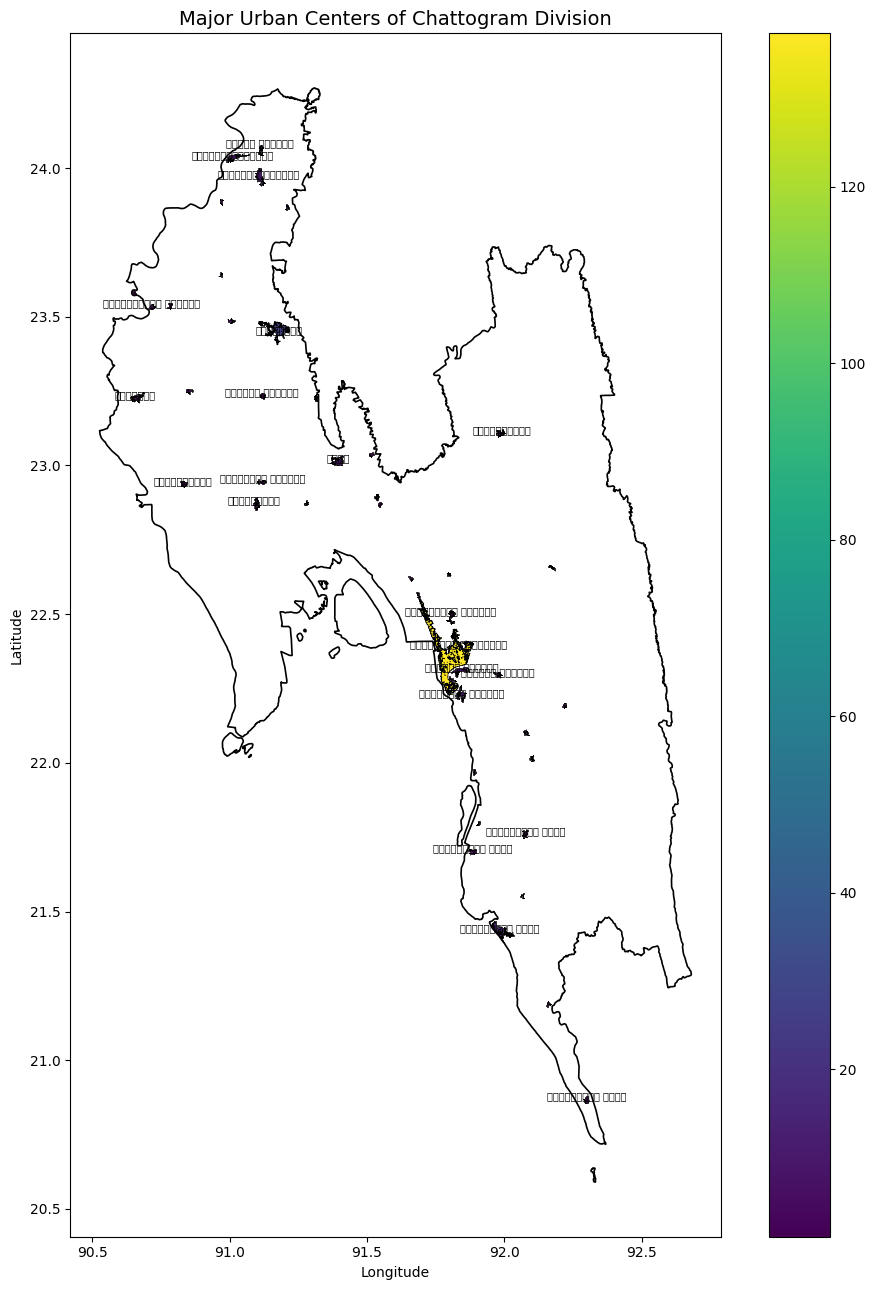


✅ Final map saved.

FINAL CHATTOGRAM SUMMARY
Threshold basis     : P92.5
Threshold value     : 0.597022
Minimum patch       : 100 ha
Major urban centers : 46
Total urban area    : 292.02 km²
Largest center      : 137.41 km²
Median center area  : 1.79 km²
Names available     : 46

FINAL FILE PACKAGE

ZIP:
/content/drive/MyDrive/GEE_Chattogram_Urban/FINAL_OUTPUTS/Chattogram_Final_Urban_Center_All_Outputs.zip
ZIP size: 3.42 MB

Included files:
 - Chattogram_Final_46_Named_Urban_Centers.shp
 - Chattogram_Final_46_Named_Urban_Centers.shx
 - Chattogram_Final_46_Named_Urban_Centers.dbf
 - Chattogram_Final_46_Named_Urban_Centers.cpg
 - Chattogram_Final_46_Named_Urban_Centers.prj
 - Chattogram_Final_46_Named_Urban_Centers.gpkg
 - Chattogram_Final_46_Representative_Points.shp
 - Chattogram_Final_46_Representative_Points.shx
 - Chattogram_Final_46_Representative_Points.dbf
 - Chattogram_Final_46_Representative_Points.cpg
 - Chattogram_Final_46_Representative_Points.prj
 - Chattogram_Final_Urban_

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
# ============================================================
# CELL 35 — FINAL CHATTOGRAM OUTPUT PACKAGE
#
# Final method:
# P92.5 threshold
# Major urban centers >= 100 ha
#
# Mask:
# 0   = Non-Urban
# 1   = Urban
# 255 = Outside Chattogram
# ============================================================

import os
import glob
import zipfile
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

from google.colab import files

print("=" * 75)
print("FINAL CHATTOGRAM URBAN CENTER OUTPUT PACKAGE")
print("=" * 75)

# ------------------------------------------------------------
# 1. Final output folder
# ------------------------------------------------------------

FINAL_PACKAGE_DIR = (
    "/content/drive/MyDrive/"
    "GEE_Chattogram_Urban/"
    "FINAL_OUTPUTS"
)

os.makedirs(
    FINAL_PACKAGE_DIR,
    exist_ok=True
)

print("\nOutput folder:")
print(FINAL_PACKAGE_DIR)

# ============================================================
# 2. SAVE FINAL URBAN SCORE TIFF
# ============================================================

SCORE_TIF_FINAL = os.path.join(
    FINAL_PACKAGE_DIR,
    "Chattogram_Final_Urban_Score_100m.tif"
)

score_profile = {
    "driver": "GTiff",
    "height": height,
    "width": width,
    "count": 1,
    "dtype": "float32",
    "crs": "EPSG:6933",
    "transform": transform_6933,
    "nodata": -9999.0,
    "compress": "lzw"
}

score_output = np.where(
    np.isfinite(urban_score_6933),
    urban_score_6933,
    -9999.0
).astype("float32")

with rasterio.open(
    SCORE_TIF_FINAL,
    "w",
    **score_profile
) as dst:

    dst.write(
        score_output,
        1
    )

    dst.set_band_description(
        1,
        "Urban_Score"
    )

print("\n✅ Final Urban Score TIFF saved.")

# ============================================================
# 3. FINAL FULL URBAN / NON-URBAN MASK
# ============================================================

FINAL_MASK_TIF = os.path.join(
    FINAL_PACKAGE_DIR,
    "Chattogram_Final_Major_Urban_Center_Mask.tif"
)

# Start everything as NoData
final_major_mask_full = np.full(
    (height, width),
    255,
    dtype="uint8"
)

# Entire Chattogram Division = Non-Urban
final_major_mask_full[
    boundary_mask_6933 == 1
] = 0

# Major urban centers = Urban
final_major_mask_full[
    (boundary_mask_6933 == 1)
    & major_mask
] = 1

mask_profile = score_profile.copy()

mask_profile.update(
    dtype="uint8",
    nodata=255
)

with rasterio.open(
    FINAL_MASK_TIF,
    "w",
    **mask_profile
) as dst:

    dst.write(
        final_major_mask_full,
        1
    )

    dst.set_band_description(
        1,
        "Major_Urban_Center_Mask"
    )

print("✅ Full Urban / Non-Urban mask saved.")

# ------------------------------------------------------------
# Mask check
# ------------------------------------------------------------

urban_pixels_final = int(
    np.sum(
        final_major_mask_full == 1
    )
)

nonurban_pixels_final = int(
    np.sum(
        final_major_mask_full == 0
    )
)

nodata_pixels_final = int(
    np.sum(
        final_major_mask_full == 255
    )
)

print("\nMask values:")
print("0   = Non-Urban")
print("1   = Urban")
print("255 = Outside Division")

print("\nPixel counts:")
print("Non-Urban :", nonurban_pixels_final)
print("Urban     :", urban_pixels_final)
print("NoData    :", nodata_pixels_final)

print(
    "Urban area:",
    round(
        urban_pixels_final * 0.01,
        2
    ),
    "km²"
)

# ============================================================
# 4. SAVE FINAL NAMED SHAPEFILE
# ============================================================

FINAL_NAMED_SHP = os.path.join(
    FINAL_PACKAGE_DIR,
    "Chattogram_Final_46_Named_Urban_Centers.shp"
)

final_named_chattogram.to_file(
    FINAL_NAMED_SHP,
    driver="ESRI Shapefile"
)

print("\n✅ Final named shapefile saved.")

# ============================================================
# 5. SAVE FINAL GEOPACKAGE
# ============================================================

FINAL_NAMED_GPKG = os.path.join(
    FINAL_PACKAGE_DIR,
    "Chattogram_Final_46_Named_Urban_Centers.gpkg"
)

final_named_chattogram.to_file(
    FINAL_NAMED_GPKG,
    layer="urban_centers",
    driver="GPKG"
)

print("✅ Final GeoPackage saved.")

# ============================================================
# 6. FINAL REPRESENTATIVE POINTS
# ============================================================

final_points = (
    final_named_chattogram
    .copy()
)

final_points["geometry"] = (
    final_points.geometry
    .representative_point()
)

final_points = (
    final_points
    .to_crs("EPSG:4326")
)

final_points["longitude"] = (
    final_points.geometry.x
)

final_points["latitude"] = (
    final_points.geometry.y
)

FINAL_POINT_SHP = os.path.join(
    FINAL_PACKAGE_DIR,
    "Chattogram_Final_46_Representative_Points.shp"
)

final_points[
    [
        "center_id",
        "urban_name",
        "area_ha",
        "area_km2",
        "longitude",
        "latitude",
        "geometry"
    ]
].to_file(
    FINAL_POINT_SHP,
    driver="ESRI Shapefile"
)

print(
    "✅ Final representative-point shapefile saved."
)

# ============================================================
# 7. FINAL CSV TABLE
# ============================================================

FINAL_TABLE_CSV = os.path.join(
    FINAL_PACKAGE_DIR,
    "Chattogram_Final_46_Urban_Centers_Table.csv"
)

final_points.drop(
    columns="geometry"
).to_csv(
    FINAL_TABLE_CSV,
    index=False
)

print("✅ Final CSV table saved.")

# ============================================================
# 8. FINAL MAP
# ============================================================

map_centers = (
    final_named_chattogram
    .to_crs("EPSG:4326")
)

boundary_map = (
    chattogram_wgs84
    .copy()
)

fig, ax = plt.subplots(
    figsize=(10, 13)
)

# Division boundary
boundary_map.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=1.2
)

# Urban centers
map_centers.plot(
    ax=ax,
    column="area_km2",
    legend=True,
    edgecolor="black",
    linewidth=0.5
)

# Label the larger centers
label_centers = map_centers[
    map_centers["area_km2"] >= 2.0
]

for _, row in label_centers.iterrows():

    p = row.geometry.representative_point()

    ax.text(
        p.x,
        p.y,
        str(row["urban_name"]),
        fontsize=7,
        ha="center"
    )

ax.set_title(
    "Major Urban Centers of Chattogram Division",
    fontsize=14
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()

FINAL_MAP_PNG = os.path.join(
    FINAL_PACKAGE_DIR,
    "Chattogram_Final_Major_Urban_Centers_Map.png"
)

plt.savefig(
    FINAL_MAP_PNG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✅ Final map saved.")

# ============================================================
# 9. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("FINAL CHATTOGRAM SUMMARY")
print("=" * 75)

print("Threshold basis     : P92.5")
print(
    "Threshold value     :",
    round(P925, 6)
)

print("Minimum patch       : 100 ha")

print(
    "Major urban centers :",
    len(final_named_chattogram)
)

print(
    "Total urban area    :",
    round(
        final_named_chattogram[
            "area_km2"
        ].sum(),
        2
    ),
    "km²"
)

print(
    "Largest center      :",
    round(
        final_named_chattogram[
            "area_km2"
        ].max(),
        2
    ),
    "km²"
)

print(
    "Median center area  :",
    round(
        final_named_chattogram[
            "area_km2"
        ].median(),
        2
    ),
    "km²"
)

print(
    "Names available     :",
    final_named_chattogram[
        "urban_name"
    ].notna().sum()
)

# ============================================================
# 10. CREATE ZIP PACKAGE
# ============================================================

files_to_zip = []

# Shapefile components
for base_name in [
    "Chattogram_Final_46_Named_Urban_Centers",
    "Chattogram_Final_46_Representative_Points"
]:

    files_to_zip.extend(
        glob.glob(
            os.path.join(
                FINAL_PACKAGE_DIR,
                base_name + ".*"
            )
        )
    )

# Other outputs
files_to_zip.extend([
    SCORE_TIF_FINAL,
    FINAL_MASK_TIF,
    FINAL_NAMED_GPKG,
    FINAL_TABLE_CSV,
    FINAL_MAP_PNG
])

# Remove duplicates
files_to_zip = list(
    dict.fromkeys(
        files_to_zip
    )
)

ZIP_FILE = os.path.join(
    FINAL_PACKAGE_DIR,
    "Chattogram_Final_Urban_Center_All_Outputs.zip"
)

with zipfile.ZipFile(
    ZIP_FILE,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for fp in files_to_zip:

        if os.path.isfile(fp):

            z.write(
                fp,
                arcname=os.path.basename(fp)
            )

print("\n" + "=" * 75)
print("FINAL FILE PACKAGE")
print("=" * 75)

print("\nZIP:")
print(ZIP_FILE)

print(
    "ZIP size:",
    round(
        os.path.getsize(ZIP_FILE)
        / (1024 * 1024),
        2
    ),
    "MB"
)

print("\nIncluded files:")

with zipfile.ZipFile(
    ZIP_FILE,
    "r"
) as z:

    for name in z.namelist():
        print(" -", name)

print(
    "\n✅ ALL FINAL CHATTOGRAM OUTPUTS READY."
)

# ============================================================
# 11. DOWNLOAD ZIP
# ============================================================

files.download(
    ZIP_FILE
)